In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import models, datasets, transforms

from pathlib import Path
from PIL import Image

import matplotlib.pyplot as plt
import sklearn.metrics
from torchvision.transforms import v2
import hashlib
import time, warnings
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

import timm

# creamos la carpeta para los resultados si no existe
Path("results").mkdir(exist_ok=True)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(DEVICE)

cuda


/home/unai/Documentos/UNI/MIARFID/RFA/.rfa_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# EDA: análisis exploratorio de los datos


In [2]:
# creamos un dataframe para almacenar la ruta de cada imagen, si es training o testing y su clase
filas = [{"ruta": str(p), "particion": p.parent.parent.name, "clase": p.parent.name}
         for p in Path("./data").glob("*/*/*") if p.is_file()]
df = pd.DataFrame(filas)
print(len(df), df["particion"].value_counts().to_dict())
df.head()

7200 {'Training': 5600, 'Testing': 1600}


,ruta,particion,clase
0,rfa_data/Testing/meningioma/Te-aug-me_16.jpg,Testing,meningioma
1,rfa_data/Testing/meningioma/Te-me_3.jpg,Testing,meningioma
2,rfa_data/Testing/meningioma/Te-me_69.jpg,Testing,meningioma
3,rfa_data/Testing/meningioma/Te-me_143.jpg,Testing,meningioma
4,rfa_data/Testing/meningioma/Te-me_34.jpg,Testing,meningioma


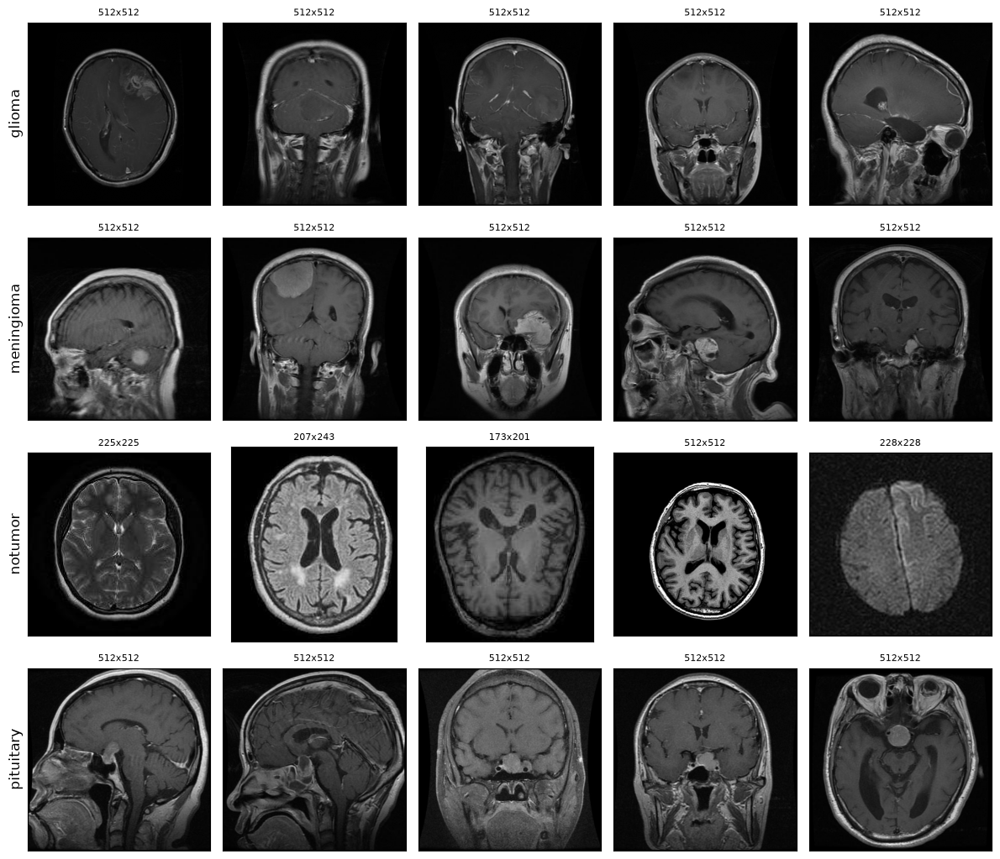

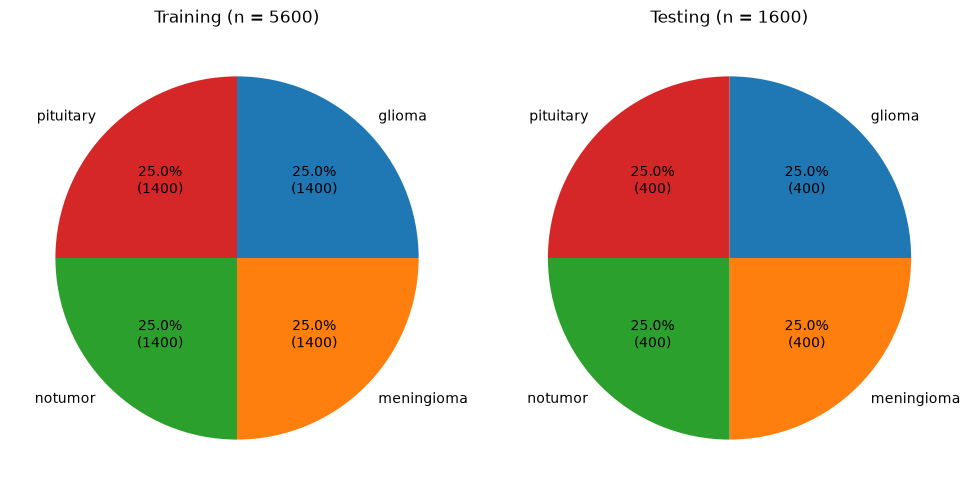

In [3]:
# mostramos ejemplo de cada una de las clases y la representación de cada clase tanto en train como en test
clases = sorted(df['clase'].unique())

# 5 ejemplos aleatorios por clase
muestra = df[df["particion"] == 'Training'].groupby('clase').head(5)
fig, axes = plt.subplots(len(clases), 5, figsize=(12, 2.6 * len(clases)))
for i, clase in enumerate(clases):
    rutas = muestra.loc[muestra["clase"] == clase, "ruta"]
    for j, ruta in enumerate(rutas):
        img = Image.open(ruta)
        ax = axes[i, j]
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{img.width}x{img.height}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    axes[i, 0].set_ylabel(clase, fontsize=12)
plt.tight_layout(); plt.show()

# mostramos representación de cada clase
conteo = pd.crosstab(df['clase'], df['particion'])[['Training', 'Testing']]
porcentajes = (conteo / conteo.sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, particion in zip(axes, conteo.columns):
    n = conteo[particion]
    ax.pie(n, labels=n.index, startangle=90, counterclock=False,
           autopct=lambda p, total=n.sum(): f"{p:.1f}%\n({round(p * total / 100)})")
    ax.set_title(f"{particion} (n = {n.sum()})")
plt.tight_layout()
plt.show()

Podemos ver que los datos estan perfectamente balanceados por lo que no debemos preocuparnos de que el modelo tenga predisposición por alguna de las clases por estar más representada que otra. Como se puede observar en las imágenes de ejemplo no siguen una resolución única, por la que tenemos que modificar las imágenes para que todas sigan una misma resolución. 

Aunque a simple vista parece que los datos estan perfectos, es importante realizar un estudio exahustivo de los mismos, para asegurarnos de que los modelos se entrenan correctamente sin fugas que produzcan resultados inflados artificialmente. 

### Búsqueda de imágenes duplicadas

Como este dataset no cuenta con identificadores por paciente, cosa que sería lo mejor para este tipo de trabajo, debemos asegurarnos de que no existen imágenes duplicadas que mejoren a los modelos artificialmente. 

Para encontrar imágenes duplicadas utilizamos dos métodos conocidos:

MD5: compara el hash generado por cada una de las imágenes para agrupar aquellas que generan el mismo y nos quedamos con una sola imagen por grupo.

pHash: comparamos los hashes generados por las imágenes y utilizamos la distancia de hamming para definir cuanto se parecen las imágenes entre ellas. 

In [4]:
def md5(ruta):
    # comprobamos si tienen el mismo hash por lo que son duplicadas
    with open(ruta, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
    
df["md5"] = df["ruta"].map(md5)
duplicado = df[df.duplicated('md5', keep=False)]
grupos = duplicado.groupby('md5').agg(n=("ruta", "size"),
    particiones=("particion", lambda s: "+".join(sorted(set(s)))),
    clases=("clase", lambda s: "+".join(sorted(set(s))))
    )
grupos['tipo'] = grupos['particiones'].map(
    lambda p: 'Training - Testing' if '+' in p else f'intra-{p}'
)
grupos["clase_distinta"] = grupos["clases"].str.contains("+", regex=False)

print(f"{len(duplicado)} imágenes con copia idéntica, en {len(grupos)} grupos")
display(pd.crosstab(grupos["tipo"], grupos["clase_distinta"], margins=True))

# Cuánto afecta al test
md5_train = set(df.loc[df["particion"] == "Training", "md5"])
test = df["particion"] == "Testing"
print(f"Testing con copia en Training: {(test & df['md5'].isin(md5_train)).sum()} de {test.sum()}")
display(grupos[grupos["clase_distinta"]])

340 imágenes con copia idéntica, en 153 grupos


clase_distinta,False,All
tipo,,
intra-Testing,15,15
intra-Training,138,138
All,153,153


Testing con copia en Training: 0 de 1600


,n,particiones,clases,tipo,clase_distinta
md5,,,,,


Según MD5 no existen copias exactas entre train y test pero seguiremos teniendo en cuenta que esto es algo posible. Tambien debemos tener en cuenta que si las copias en train a la hora de hacer el split entre entrenamiento y validación pueden caer una en cada split y producir valores demasiado optimistas, por lo que lo mejor es filtrar las copias para que esto no pueda ocurrir.

In [5]:
# primero ordenamos el dataframe para siempre conservar la misma imágen
df = df.sort_values('ruta', ignore_index=True)
df['dup_md5'] = df.duplicated('md5', keep='first')

n_antes = len(df)
print(df.groupby('particion')['dup_md5'].sum())
df = df[~df["dup_md5"]].drop(columns="dup_md5").reset_index(drop=True)

assert not df['md5'].duplicated().any()
print(f"{n_antes} - {len(df)} imágenes ({n_antes - len(df)} copias eliminadas)")


particion
Testing      16
Training    171
Name: dup_md5, dtype: int64
7200 - 7013 imágenes (187 copias eliminadas)


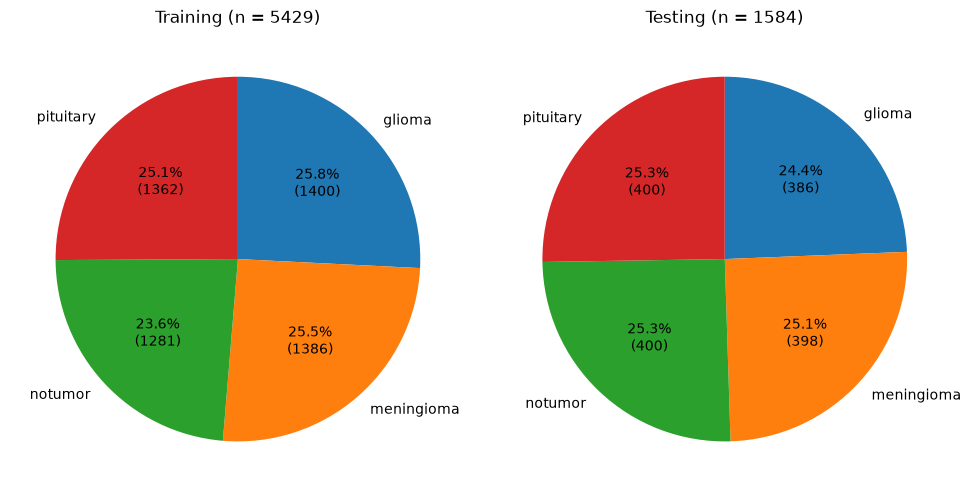

In [6]:
# Mostramos ahora como ha quedado la representación de las clases
conteo = pd.crosstab(df['clase'], df['particion'])[['Training', 'Testing']]
porcentajes = (conteo / conteo.sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, particion in zip(axes, conteo.columns):
    n = conteo[particion]
    ax.pie(n, labels=n.index, startangle=90, counterclock=False,
           autopct=lambda p, total=n.sum(): f"{p:.1f}%\n({round(p * total / 100)})")
    ax.set_title(f"{particion} (n = {n.sum()})")
plt.tight_layout()
plt.show()

In [7]:
from scipy.fft import dct

def phash(ruta, tam=32, low=8):
    img = Image.open(ruta).convert("L").resize((tam, tam), Image.LANCZOS)
    a = np.asarray(img, dtype=np.float32)
    d = dct(dct(a, axis=0, norm="ortho"), axis=1, norm="ortho")[:low, :low]
    v = d.flatten()[1:]          # se descarta el término DC (brillo medio)
    return (v > np.median(v)).astype(np.uint8)

H = np.stack(df["ruta"].map(phash).to_numpy())
print(H.shape)   # (7013, 63)

(7013, 63)


7957 pares; 1149 grupos de casi duplicados; 3596 imágenes sobrantes


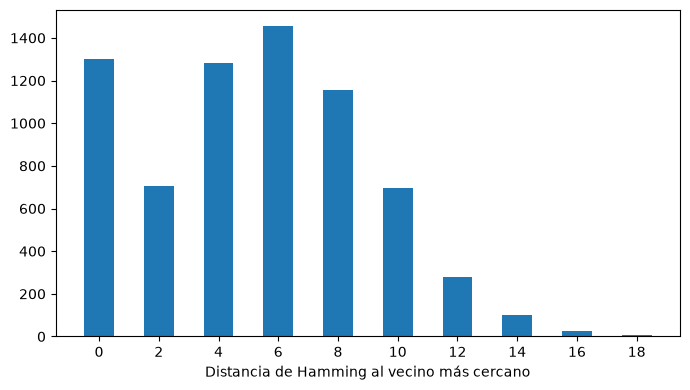

umbral 0:   1463 pares,  495 grupos,   806 sobrantes, grupo mayor: 14
umbral 1:   1463 pares,  495 grupos,   806 sobrantes, grupo mayor: 14
umbral 2:   3211 pares,  638 grupos,  1367 sobrantes, grupo mayor: 23
umbral 3:   3211 pares,  638 grupos,  1367 sobrantes, grupo mayor: 23
umbral 4:   5150 pares, 1023 grupos,  2264 sobrantes, grupo mayor: 24
umbral 5:   5150 pares, 1023 grupos,  2264 sobrantes, grupo mayor: 24
umbral 6:   7957 pares, 1149 grupos,  3596 sobrantes, grupo mayor: 181
umbral 7:   7957 pares, 1149 grupos,  3596 sobrantes, grupo mayor: 181
umbral 8:  13885 pares,  759 grupos,  5143 sobrantes, grupo mayor: 2743


In [8]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

UMBRAL = 6   # revisar antes de darlo por bueno

Hf = H.astype(np.float32)
fil, col = [], []
for s in range(0, len(Hf), 1000):
    blo = Hf[s:s+1000]
    D = blo @ (1 - Hf).T + (1 - blo) @ Hf.T     # distancia de Hamming
    a, b = np.where(D <= UMBRAL)
    a = a + s
    m = a < b
    fil.append(a[m]); col.append(b[m])
fil, col = np.concatenate(fil), np.concatenate(col)

g = csr_matrix((np.ones(len(fil)), (fil, col)), shape=(len(H), len(H)))
_, grupo = connected_components(g, directed=False)
df["grupo"] = grupo

tam = df["grupo"].value_counts()
print(f"{len(fil)} pares; {(tam > 1).sum()} grupos de casi duplicados; "
      f"{(tam[tam > 1].sum() - (tam > 1).sum())} imágenes sobrantes")

d_min = np.full(len(Hf), 63.0)
pares = {}
for s in range(0, len(Hf), 1000):
    blo = Hf[s:s+1000]
    D = blo @ (1 - Hf).T + (1 - blo) @ Hf.T
    np.fill_diagonal(D[:, s:s+len(blo)], 63)      # ignorar la propia imagen
    d_min[s:s+len(blo)] = D.min(axis=1)
    for u in range(0, 9):
        a, b = np.where(D <= u); a = a + s; m = a < b
        pares.setdefault(u, []).append(np.c_[a[m], b[m]])

plt.figure(figsize=(7, 4))
plt.hist(d_min, bins=np.arange(0, 20) - 0.5)
plt.xlabel("Distancia de Hamming al vecino más cercano"); plt.xticks(range(0, 20, 2))
plt.tight_layout(); plt.show()

for u in range(0, 9):
    p = np.vstack(pares[u]) if pares[u] else np.empty((0, 2), int)
    g = csr_matrix((np.ones(len(p)), (p[:, 0], p[:, 1])), shape=(len(H), len(H)))
    _, gr = connected_components(g, directed=False)
    t = pd.Series(gr).value_counts()
    print(f"umbral {u}: {len(p):6d} pares, {(t>1).sum():4d} grupos, "
          f"{t[t>1].sum()-(t>1).sum():5d} sobrantes, grupo mayor: {t.max()}")

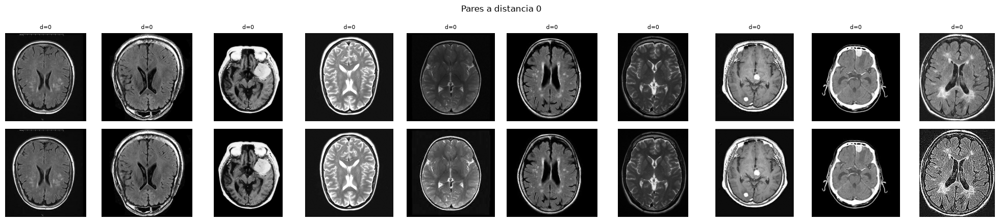

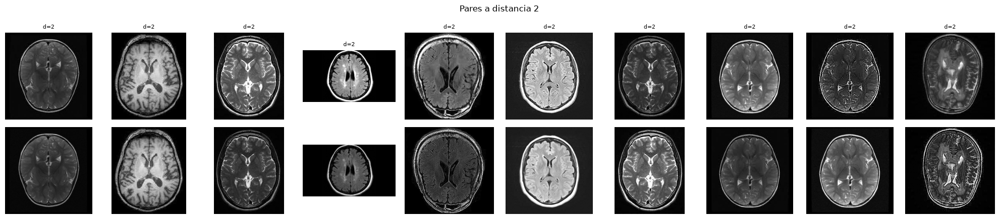

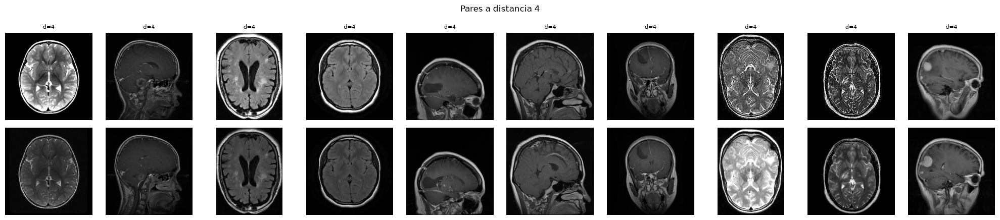

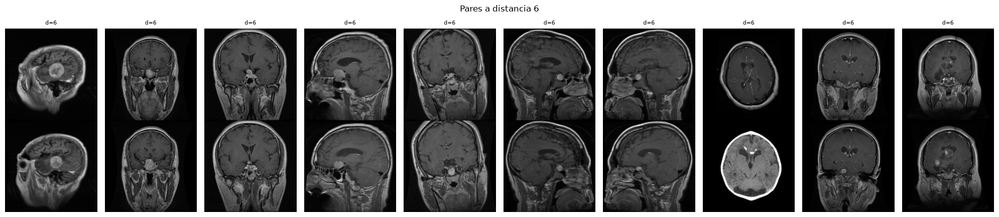

In [9]:
rutas = df["ruta"].to_numpy()

def ver_pares(d_exacta, n=10):
    p = np.vstack(pares[d_exacta]) if d_exacta > 0 else np.vstack(pares[0])
    if d_exacta > 0:
        prev = set(map(tuple, np.vstack(pares[d_exacta - 2])))
        p = np.array([q for q in p if tuple(q) not in prev])
    sel = np.random.default_rng().choice(len(p), min(n, len(p)), replace=False)
    fig, axs = plt.subplots(2, len(sel), figsize=(2 * len(sel), 4.4))
    for j, k in enumerate(sel):
        for f in (0, 1):
            axs[f, j].imshow(Image.open(rutas[p[k, f]]).convert("L"), cmap="gray")
            axs[f, j].set_axis_off()
        axs[0, j].set_title(f"d={d_exacta}", fontsize=8)
    plt.suptitle(f"Pares a distancia {d_exacta}"); plt.tight_layout(); plt.show()

for d in (0, 2, 4, 6):
    ver_pares(d)

Podemos Observar que MD5 no es capaz de captar todas las copias, ya bien por cambios de constrante u otros factores, en cambio pHash nos permite ver y estudiar la similitud entre diferentes imágenes. Hay que tener en cuenta que estos métodos no son infalibles y que la única forma de asegurarnos de que no existen copias sería ir de una en una revisando todas las imágenes. 

Viendo el desastre que es este dataset, se me ocurrio que si existen imágenes duplicadas, es muy probable que sea debido a que el creador del mismo simplemente ha id recopilando imágenes de diferentes fuentes sin demasiada atención al detalle por lo que sería posible que existan imágenes etiquetadas de forma incorrecta. 

Para comprobar esto utilizamos pHash una vez más, imprimiendo aquellas imágenes que sean "iguales" y tengan diferentes etiquetas para poder eliminarlas y no confundir a los modelos. 

Se ha decidido utilizar un umbral muy bajo para este caso, debido a que es poco probable que esto ocurra muchas veces e incluso con este umbral ya podemos ver que pHash dice que las imágenes son prácticamente iguales (distancia = 2) en casos que podemos observar que claramente no es así.

3211 pares a d<=2; 12 con clase distinta


dist,0,2,All
combo,,,
glioma / meningioma,4,8,12
All,4,8,12


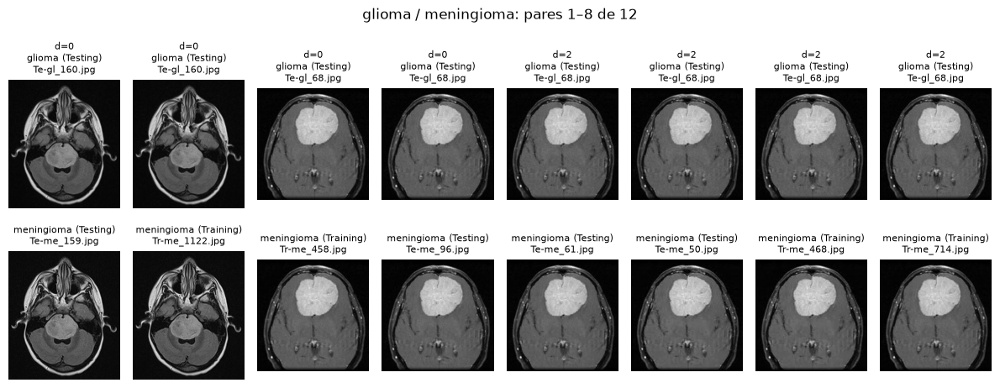

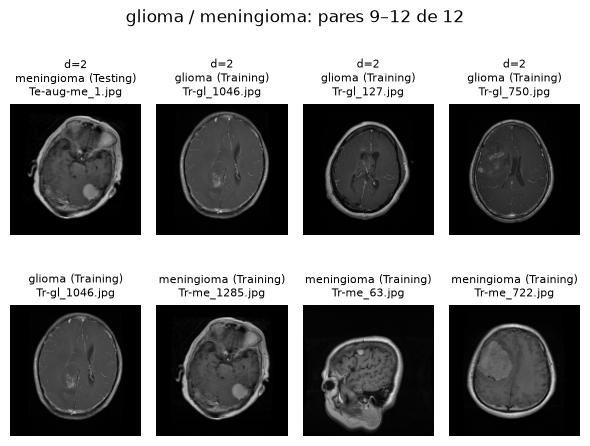

In [10]:
# Pares a d <= 2 con clase distinta. Va antes de la deduplicación por hash idéntico:
# aquí `df` tiene 7013 filas (tras quitar las copias MD5) y `H` está alineado con él.

UMBRAL = 2   # d <= 2; como las distancias son pares, incluye d = 0 y 2
N_MAX = 8    # pares que se dibujan por combinación de clases

assert len(H) == len(df), "Esta celda debe ir antes de la deduplicación por hash idéntico"
Hf = H.astype(np.float32)

# Pares (i < j) a distancia <= UMBRAL, por bloques como en la celda 10
bloques = []
for s in range(0, len(Hf), 1000):
    blo = Hf[s:s+1000]
    D = blo @ (1 - Hf).T + (1 - blo) @ Hf.T
    a, b = np.where(D <= UMBRAL)
    m = a + s < b
    bloques.append(np.c_[a[m] + s, b[m], D[a[m], b[m]]])
p = pd.DataFrame(np.vstack(bloques).astype(int), columns=["i", "j", "dist"])

clase = df["clase"].to_numpy()
particion = df["particion"].to_numpy()
rutas = df["ruta"].to_numpy()

conf = p[clase[p["i"]] != clase[p["j"]]].copy()
conf["combo"] = [" / ".join(sorted(t)) for t in zip(clase[conf["i"]], clase[conf["j"]])]

print(f"{len(p)} pares a d<={UMBRAL}; {len(conf)} con clase distinta")
display(pd.crosstab(conf["combo"], conf["dist"], margins=True))

for combo, sub in conf.groupby("combo"):
    sub = sub.sort_values("dist")
    for s in range(0, len(sub), 8):
        bloque = sub.iloc[s:s+8]
        fig, axs = plt.subplots(2, len(bloque), figsize=(1.5 * len(bloque), 5), squeeze=False)
        for col, (i, j, dist) in enumerate(bloque[["i", "j", "dist"]].to_numpy()):
            for fila, k in enumerate((i, j)):
                ax = axs[fila, col]
                ax.imshow(Image.open(rutas[k]).convert("L"), cmap="gray")
                ax.set_title((f"d={dist}\n" if fila == 0 else "") + f"{clase[k]} ({particion[k]})\n{Path(rutas[k]).name}", fontsize=8)
                ax.set_axis_off()
        plt.suptitle(f"{combo}: pares {s + 1}–{s + len(bloque)} de {len(sub)}"); plt.tight_layout(); plt.show()

In [11]:
# Se eliminan las imágenes implicadas en pares con clase distinta a d <= 2. Va antes de la
# deduplicación por hash idéntico: aquí df y H siguen alineados con los índices de `conf`.
afectadas = np.unique(conf[["i", "j"]].to_numpy())
antes = pd.crosstab(df["clase"], df["particion"])[["Training", "Testing"]]

print(f"Se eliminan {len(afectadas)} imágenes ({len(afectadas) / len(df):.1%}), "
      f"implicadas en {len(conf)} pares con clase distinta a d<={UMBRAL}")
display(pd.crosstab(df.iloc[afectadas]["clase"], df.iloc[afectadas]["particion"], margins=True))

mantener = np.ones(len(df), dtype=bool)
mantener[afectadas] = False
df = df[mantener].reset_index(drop=True)
H = H[mantener]
assert len(H) == len(df)

despues = pd.crosstab(df["clase"], df["particion"])[["Training", "Testing"]]
display(pd.concat({"antes": antes, "después": despues,
                   "% antes": (antes / antes.sum() * 100).round(1),
                   "% después": (despues / despues.sum() * 100).round(1)}, axis=1))

Se eliminan 17 imágenes (0.2%), implicadas en 12 pares con clase distinta a d<=2


particion,Testing,Training,All
clase,,,
glioma,2,3,5
meningioma,5,7,12
All,7,10,17


antes          después          % antes         % después  \
particion  Training Testing Training Testing Training Testing  Training   
clase                                                                     
glioma         1400     386     1397     384     25.8    24.4      25.8   
meningioma     1386     398     1379     393     25.5    25.1      25.4   
notumor        1281     400     1281     400     23.6    25.3      23.6   
pituitary      1362     400     1362     400     25.1    25.3      25.1   

                    
particion  Testing  
clase               
glioma        24.4  
meningioma    24.9  
notumor       25.4  
pituitary     25.4

In [12]:
df["phash"] = [h.tobytes() for h in H]
df["grupo"] = pd.factorize(df["phash"])[0]

tam = df["grupo"].value_counts()
print(f"{(tam > 1).sum()} grupos de hash idéntico; "
      f"{tam[tam > 1].sum() - (tam > 1).sum()} imágenes sobrantes")

# Cuántos grupos cruzan particiones o mezclan clases
gr = df.groupby("grupo").agg(n=("ruta", "size"),
                             parts=("particion", "nunique"),
                             clases=("clase", "nunique"))
gr = gr[gr["n"] > 1]
print(f"grupos que cruzan Training/Testing: {(gr['parts'] > 1).sum()}")
print(f"grupos con más de una clase:        {(gr['clases'] > 1).sum()}")

orden = {"Training": 0, "Testing": 1}
df = (df.sort_values(["grupo", "particion", "ruta"],
                     key=lambda s: s.map(orden) if s.name == "particion" else s)
        .drop_duplicates("grupo", keep="first")
        .reset_index(drop=True))
print(len(df))

491 grupos de hash idéntico; 798 imágenes sobrantes
grupos que cruzan Training/Testing: 288
grupos con más de una clase:        0
6198


Viendo el estado de las imágenes, el mayor peligro ahora mismo es la fuga tanto en validación como en test que simulen unos resultados altamente optimistas y una generalización del modelo que no es real. 

Por lo que se ha tomado la decisión de agrupar aquellas imágenes con distancia <= 6, es decir todas las imágenes con una distancia menor o igual a 6 se agrupan en train para evitar la fuga en val y si algunas de estas imágenes se encuentran en test, se marcan como "casi copias" para realizar dos comprobaciones finales:

1. Con el Test entero.
2. Con el Test sin las casi-copias para intentar obtener una visión realista de la generalización del modelo. 

In [13]:
from sklearn.model_selection import StratifiedGroupKFold
T_GRUPO = 6   # las casi-copias a d <= T_GRUPO caen siempre del mismo lado de la partición

# pHash alineado con el df actual (la deduplicación por hash idéntico reordena df, así que H ya no lo está)
Hg = np.stack([np.frombuffer(h, dtype=np.uint8) for h in df["phash"]]).astype(np.float32)

# Grupos de casi-copias dentro de Training: componentes conexas del grafo d <= T_GRUPO
idx_training = np.where(df["particion"] == "Training")[0]
Ht = Hg[idx_training]
fil, col = [], []
for s in range(0, len(Ht), 1000):
    D = Ht[s:s+1000] @ (1 - Ht).T + (1 - Ht[s:s+1000]) @ Ht.T
    a, b = np.where(D <= T_GRUPO)
    fil.append(a + s); col.append(b)
fil, col = np.concatenate(fil), np.concatenate(col)
g = csr_matrix((np.ones(len(fil)), (fil, col)), shape=(len(Ht), len(Ht)))
_, grupos = connected_components(g, directed=False)

tam = pd.Series(grupos).value_counts()
print(f"{len(tam)} grupos en Training; {(tam > 1).sum()} con más de una imagen "
      f"({tam[tam > 1].sum()} imágenes); grupo mayor: {tam.max()}")

# Un fold de 5 como validación (20 %), estratificado por clase y sin partir ningún grupo
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr, va = next(sgkf.split(idx_training, df["clase"].to_numpy()[idx_training], groups=grupos))

df["split"] = "test"
df.loc[idx_training[tr], "split"] = "train"
df.loc[idx_training[va], "split"] = "val"

display(pd.crosstab(df["clase"], df["split"], margins=True))
display((pd.crosstab(df["clase"], df["split"], normalize="columns") * 100).round(1))

# Verificación
assert (df.loc[df["split"] != "test", "particion"] == "Training").all()
assert (df.loc[df["split"] == "test", "particion"] == "Testing").all()
assert not set(grupos[tr]) & set(grupos[va]), "Algún grupo está a la vez en train y en val"

3035 grupos en Training; 832 con más de una imagen (2816 imágenes); grupo mayor: 112


split,test,train,val,All
clase,,,,
glioma,376,1003,390,1769
meningioma,292,1048,319,1659
notumor,113,742,168,1023
pituitary,398,1099,250,1747
All,1179,3892,1127,6198


split,test,train,val
clase,,,
glioma,31.9,25.8,34.6
meningioma,24.8,26.9,28.3
notumor,9.6,19.1,14.9
pituitary,33.8,28.2,22.2


In [14]:
# Casi-copias entre test y Training (train + val): ninguna imagen de test debería tener una a d <= T_GRUPO
i_te  = np.where(df["split"] == "test")[0]
i_trv = np.where(df["split"] != "test")[0]

D = Hg[i_te] @ (1 - Hg[i_trv]).T + (1 - Hg[i_te]) @ Hg[i_trv].T
d_min = D.min(axis=1).astype(int)
fuga = d_min <= T_GRUPO

print(f"{fuga.sum()} de {len(i_te)} imágenes de test tienen casi-copia en train/val (d <= {T_GRUPO})")
if fuga.any():
    display(pd.crosstab(df["clase"].to_numpy()[i_te][fuga], d_min[fuga],
                        rownames=["clase"], colnames=["d"], margins=True))

588 de 1179 imágenes de test tienen casi-copia en train/val (d <= 6)


d,2,4,6,All
clase,,,,
glioma,18,57,88,163
meningioma,18,47,69,134
notumor,58,17,11,86
pituitary,25,75,105,205
All,119,196,273,588


Los resultados muestran que casi la mitad del Test tiene una imagen que se puede considerar una casi copia de alguna imagen de train. Obviamente no se puede asegurar que muchas de estas sean realmente copias, pero lo más honesto es incluirlas aunque puedan ser falsos positivos ya que esta es la única forma de asegurarnos que el modelo no obtiene un resultado optimista inflado artificialmente. 

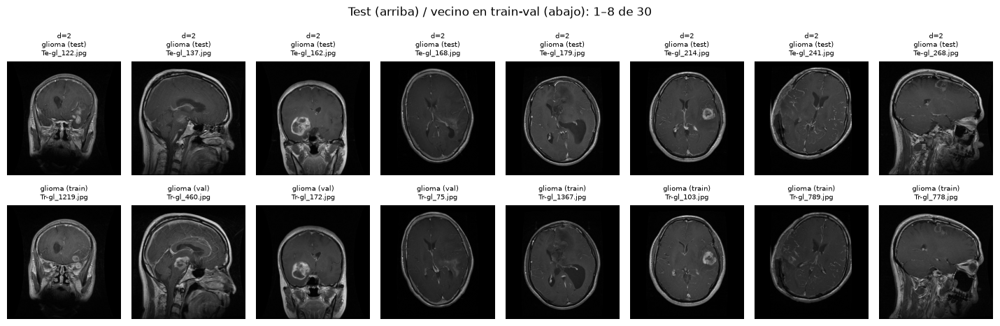

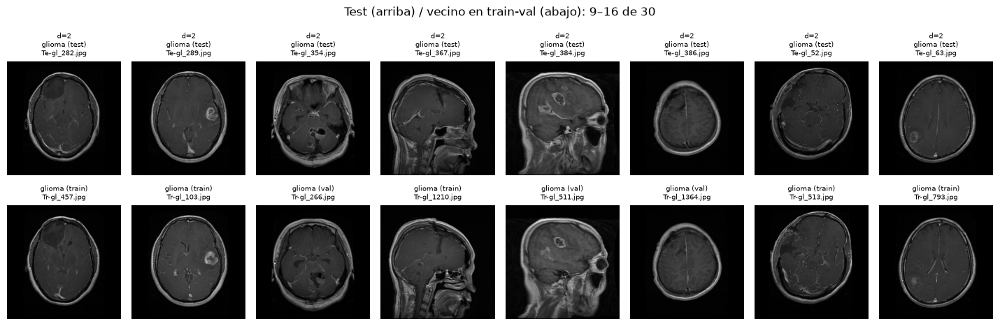

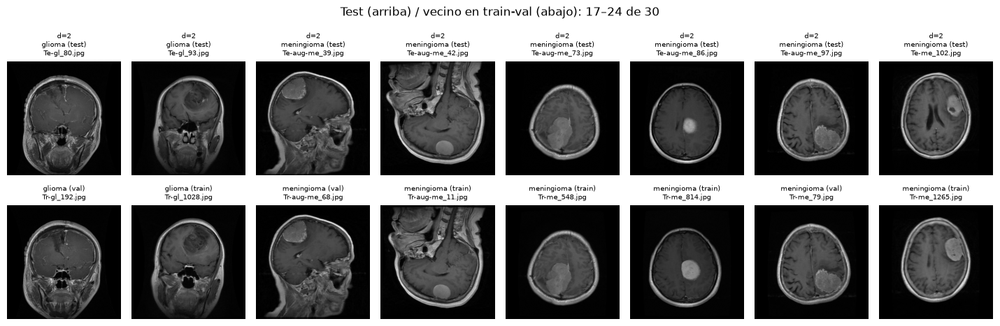

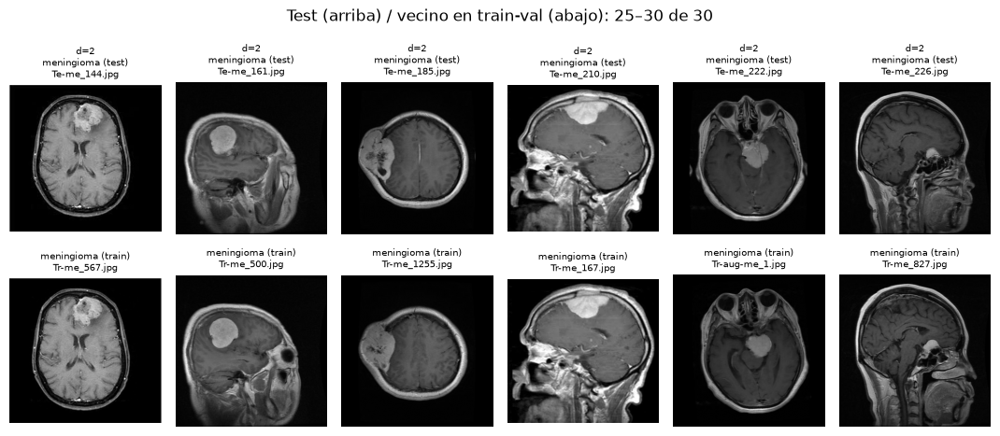

In [15]:
rutas_df, clase_df, split_df = df["ruta"].to_numpy(), df["clase"].to_numpy(), df["split"].to_numpy()

vecino = i_trv[D.argmin(axis=1)]            # vecino más cercano en train/val de cada imagen de test
sel = np.where(fuga)[0]
sel = sel[np.argsort(d_min[sel], kind="stable")]
sel = sel[:30]

for s in range(0, len(sel), 8):
    bloque = sel[s:s+8]
    fig, axs = plt.subplots(2, len(bloque), figsize=(1.8 * len(bloque), 5), squeeze=False)
    for c, k in enumerate(bloque):
        for f, idx in enumerate((i_te[k], vecino[k])):
            ax = axs[f, c]
            ax.imshow(Image.open(rutas_df[idx]).convert("L"), cmap="gray")
            ax.set_title((f"d={d_min[k]}\n" if f == 0 else "")
                         + f"{clase_df[idx]} ({split_df[idx]})\n{Path(rutas_df[idx]).name}", fontsize=7)
            ax.set_axis_off()
    plt.suptitle(f"Test (arriba) / vecino en train-val (abajo): {s + 1}–{s + len(bloque)} de {len(sel)}")
    plt.tight_layout(); plt.show()

In [16]:
df["casi_copia"] = False
df.loc[i_te[fuga], "casi_copia"] = True

test = df["split"] == "test"
display(pd.crosstab(df.loc[test, "clase"], df.loc[test, "casi_copia"], margins=True))

casi_copia,False,True,All
clase,,,
glioma,213,163,376
meningioma,158,134,292
notumor,27,86,113
pituitary,193,205,398
All,591,588,1179


In [17]:
i_tr = np.where(df["split"] == "train")[0]
i_va = np.where(df["split"] == "val")[0]

# Por construcción, ninguna imagen de val tiene casi-copia (pHash d <= T_GRUPO) en train
D = Hg[i_va] @ (1 - Hg[i_tr]).T + (1 - Hg[i_va]) @ Hg[i_tr].T
assert not (D <= T_GRUPO).any()

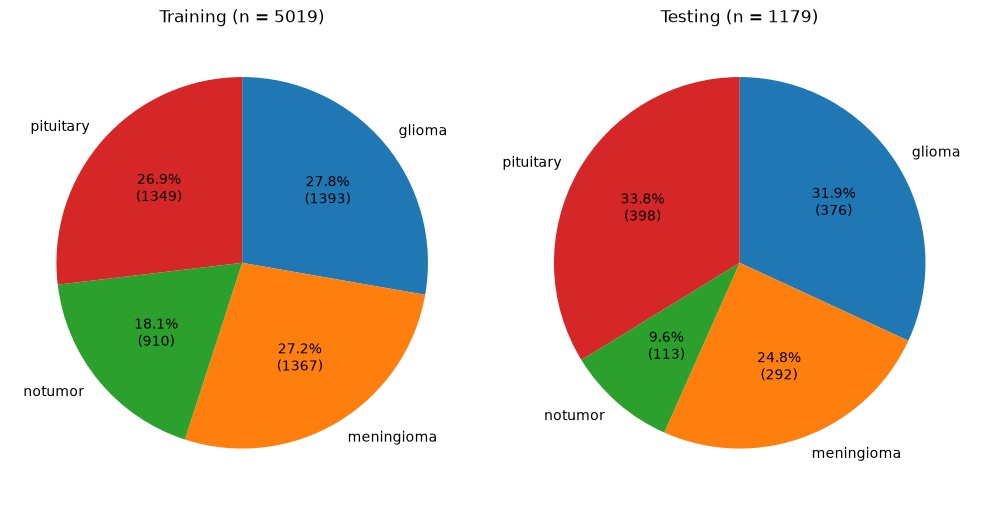

In [18]:
# Mostramos ahora como ha quedado la representación de las clases
conteo = pd.crosstab(df['clase'], df['particion'])[['Training', 'Testing']]
porcentajes = (conteo / conteo.sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, particion in zip(axes, conteo.columns):
    n = conteo[particion]
    ax.pie(n, labels=n.index, startangle=90, counterclock=False,
           autopct=lambda p, total=n.sum(): f"{p:.1f}%\n({round(p * total / 100)})")
    ax.set_title(f"{particion} (n = {n.sum()})")
plt.tight_layout()
plt.show()

Con los cambios realizados al dataset podemos ver que la visión ahora es que el dataset esta más desbalanceado de lo que esperabamos, siendo "notumor" la clase menos representada tanto en train como en test. 

In [19]:
df[["ruta", "particion", "clase", "md5", "phash", "split", "casi_copia"]].to_csv("splits.csv", index=False)

Hacemos una última validación para asegurarnos de que los splits están bien formados y no existen fugas.

In [20]:
# Verificación independiente sobre splits.csv (lo que leen E1, E2 y E3)
s = pd.read_csv("splits.csv")
H = np.stack([phash(r) for r in s["ruta"]]).astype(np.float32)
D = H @ (1 - H).T + (1 - H) @ H.T
np.fill_diagonal(D, 63)
sp = s["split"].to_numpy()
tr, va, te = sp == "train", sp == "val", sp == "test"
cl = s["clase"].to_numpy()

assert not s["md5"].duplicated().any(), "Quedan copias exactas (MD5)"
assert D.min() > 0, "Quedan imágenes con pHash idéntico"
assert D[np.ix_(va, tr)].min() > T_GRUPO, "Hay casi-copias entre train y val"
assert not ((D <= 2) & (cl[:, None] != cl[None, :])).any(), "Quedan pares a d <= 2 con clase distinta"
assert (s.loc[te, "casi_copia"].to_numpy() == (D[np.ix_(te, tr | va)].min(axis=1) <= T_GRUPO)).all(), "casi_copia no coincide"
print(f"OK. Distancia mínima val–train: {D[np.ix_(va, tr)].min():.0f}")

OK. Distancia mínima val–train: 8


# E1: PCA y modelos lineales

Como primer experimento y siguiendo la estructura de las prácticas se plantea la reducción de dimensiones mediante PCA y sobre esta representación se prueban 3 clasificadores clásicos: LDA y regresión logística (lineales) y QDA (cuadrático).

Cada imagen pasa la misma transformación que van a pasar las imágenes para todos los modelos presentes en el trabajo. Cabe esperar unos resultados claramente inferiores a los obtenidos por los siguientes métodos desarrollados en este trabajo, por lo que el objetivo principal es observar cuánto aportan estos métodos más complejos sobre el baseline (E1).

In [21]:
# Las cachés dependen del split; se borran al cambiar la deduplicación o TRANSFORMAR
for f in Path(".").glob("cache_*_224*.npz"):
    f.unlink()
    print("borrado", f.name)

borrado cache_val_224.npz
borrado cache_test_224.npz
borrado cache_train_224.npz


In [22]:
RES = 224
resize = v2.Resize((224,224))
df = pd.read_csv("splits.csv")
clases = sorted(df['clase'].unique())
clase_a_idx = {c: i for i, c in enumerate(clases)}

def cargar(subconjunto):
    cache = Path(f"cache_{subconjunto}_{RES}.npz")
    if cache.exists():
        d = np.load(cache)
        return d["X"], d["y"]
    sub = df[df["split"] == subconjunto]
    X = np.stack([np.asarray(resize(Image.open(r).convert("L")), dtype=np.float32).ravel() / 255.0
                  for r in sub["ruta"]])
    y = sub['clase'].map(clase_a_idx).to_numpy()
    np.savez(cache, X=X, y=y)
    return X, y

X_train, y_train = cargar("train")
X_val,   y_val   = cargar("val")
X_test,  y_test  = cargar("test")

print(X_train.shape, X_val.shape, X_test.shape)
print(f"{X_train.nbytes / 1e6:.0f} MB en train")
assert X_train.shape[1] == RES * RES

(3892, 50176) (1127, 50176) (1179, 50176)
781 MB en train


K= 10: 0.427 de varianza explicada
K= 25: 0.525 de varianza explicada
K= 50: 0.613 de varianza explicada
K=100: 0.706 de varianza explicada
K=200: 0.799 de varianza explicada
K=300: 0.849 de varianza explicada
K=400: 0.881 de varianza explicada
K=500: 0.903 de varianza explicada
K=600: 0.919 de varianza explicada
K=700: 0.932 de varianza explicada
K=800: 0.942 de varianza explicada
K=1000: 0.956 de varianza explicada
K=1200: 0.966 de varianza explicada
K=1500: 0.976 de varianza explicada


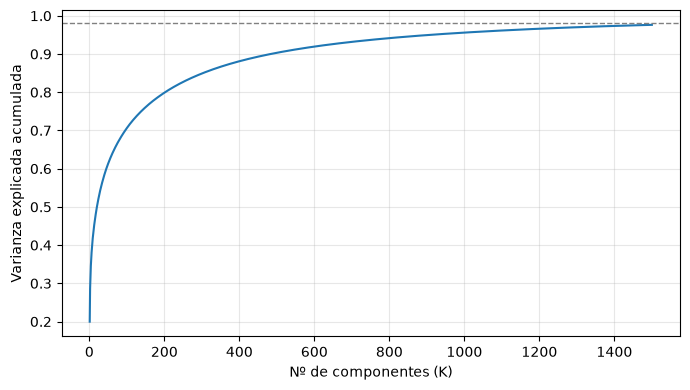

In [23]:
from sklearn.decomposition import PCA

K_MAX = 1500
pca = PCA(n_components=K_MAX, svd_solver="randomized", random_state=SEED).fit(X_train)

Z_train = pca.transform(X_train)
Z_val   = pca.transform(X_val)
Z_test  = pca.transform(X_test)

var_acum = np.cumsum(pca.explained_variance_ratio_)
for k in (10, 25, 50, 100, 200, 300, 400, 500, 600, 700, 800, 1000, 1200, 1500):
    print(f"K={k:3d}: {var_acum[k-1]:.3f} de varianza explicada")

plt.figure(figsize=(7, 4))
plt.plot(range(1, K_MAX + 1), var_acum)
plt.axhline(0.98, ls="--", c="gray", lw=1)
plt.xlabel("Nº de componentes (K)"); plt.ylabel("Varianza explicada acumulada")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

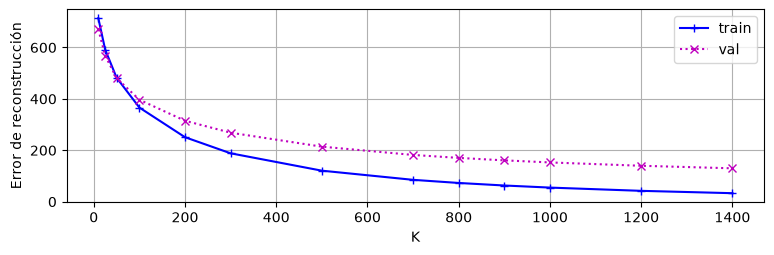

In [24]:
Ks = np.array([10, 25, 50, 100, 200, 300, 500, 700, 800, 900, 1000, 1200, 1400])
L_train = np.empty(len(Ks)); L_val = np.empty(len(Ks))

for i, K in enumerate(Ks):
    Zk = Z_train.copy(); Zk[:, K:] = 0.0
    L_train[i] = np.square(X_train - pca.inverse_transform(Zk)).sum(axis=1).mean()
    Zk = Z_val.copy(); Zk[:, K:] = 0.0
    L_val[i] = np.square(X_val - pca.inverse_transform(Zk)).sum(axis=1).mean()

plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, L_train, "+-b", label="train"); plt.plot(Ks, L_val, "x:m", label="val")
plt.xlabel("K"); plt.ylabel("Error de reconstrucción"); plt.legend(); plt.show()

Para elegir cuántas componentes conservar, primero miramos la **varianza explicada acumulada**: el porcentaje de la varianza total de los datos de entrenamiento (la suma de las varianzas de los 50 176 píxeles) que recogen las K primeras componentes principales. Equivale a cuánta de la variabilidad entre imágenes se conserva al proyectarlas en K dimensiones; el resto se pierde.

La varianza está muy repartida entre las componentes: las 50 primeras recogen el 61 % de la varianza total, hacen falta unas 500 para llegar al 90 % y ni con 1500 se alcanza el 98 % (97,6%). Esto contrasta con datasets más sencillos como MNIST (práctica TL02), donde unos pocos cientos de componentes recogen casi toda la variabilidad. Es lo esperable en imágenes médicas de alta resolución, con mucha variación de anatomía, corte, contraste y encuadre. Por tanto, la varianza explicada no basta para elegir K, y lo estudiamos también con el error de reconstrucción y, sobre todo, con el resultado de los clasificadores en validación.

In [66]:
Ks = [50, 100, 200, 300, 500, 800,1000, 1200]
rejilla = {
    "LDA":    ("shrinkage", [None, "auto", 0.1, 0.3, 0.5, 0.8],
               lambda v: LDA(solver="lsqr", shrinkage=v)),
    "QDA":    ("reg_param", [0.01, 0.1, 0.3, 0.5, 0.7, 0.9],
               lambda v: QDA(reg_param=v)),
    "LogReg": ("C", [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 0.1, 1],
               lambda v: LogisticRegression(C=v, max_iter=2000)),
}

filas = []
for K in Ks:
    for modelo, (nombre_p, valores, crear) in rejilla.items():
        for v in valores:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                clf = crear(v).fit(Z_train[:, :K], y_train)
            pred = clf.predict(Z_val[:, :K])
            filas.append({"K": K, "modelo": modelo, "param": f"{nombre_p}={v}",
                          "acc": accuracy_score(y_val, pred),
                          "f1": f1_score(y_val, pred, average="macro")})
grid = pd.DataFrame(filas)
mejores_e1 = grid.loc[grid.groupby("modelo")["f1"].idxmax()]
display(mejores_e1.round(4))

# Top 3 por modelo, para ver si el ganador destaca o está empatado con otros
display(grid.sort_values(["modelo", "f1"], ascending=[True, False])
            .groupby("modelo").head(3).round(4))

,K,modelo,param,acc,f1
61,300,LDA,shrinkage=0.5,0.7507,0.7518
72,300,LogReg,C=0.003,0.7773,0.7747
87,500,QDA,reg_param=0.9,0.7888,0.8016


,K,modelo,param,acc,f1
61,300,LDA,shrinkage=0.5,0.7507,0.7518
138,1200,LDA,shrinkage=0.8,0.7471,0.7488
119,1000,LDA,shrinkage=0.8,0.7453,0.7467
72,300,LogReg,C=0.003,0.7773,0.7747
90,500,LogReg,C=0.001,0.7755,0.7727
71,300,LogReg,C=0.001,0.7746,0.7725
87,500,QDA,reg_param=0.9,0.7888,0.8016
106,800,QDA,reg_param=0.9,0.7870,0.7994
68,300,QDA,reg_param=0.9,0.7817,0.7954


Para encontrar la mejor configuración para cada modelo realizamos una búsqueda de hiperparámetros en función de K y comparamos cada modelo con su mejor K e hiperparámetros.


=== LDA (K=300, shrinkage=0.5)
              precision    recall  f1-score   support

      glioma      0.782     0.782     0.782       390
  meningioma      0.638     0.646     0.642       319
     notumor      0.825     0.673     0.741       168
   pituitary      0.801     0.888     0.843       250

    accuracy                          0.751      1127
   macro avg      0.762     0.747     0.752      1127
weighted avg      0.752     0.751     0.750      1127


=== LogReg (K=300, C=0.003)
              precision    recall  f1-score   support

      glioma      0.822     0.815     0.819       390
  meningioma      0.669     0.671     0.670       319
     notumor      0.768     0.708     0.737       168
   pituitary      0.849     0.900     0.874       250

    accuracy                          0.777      1127
   macro avg      0.777     0.774     0.775      1127
weighted avg      0.776     0.777     0.777      1127


=== QDA (K=500, reg_param=0.9)
              precision    recall  f1

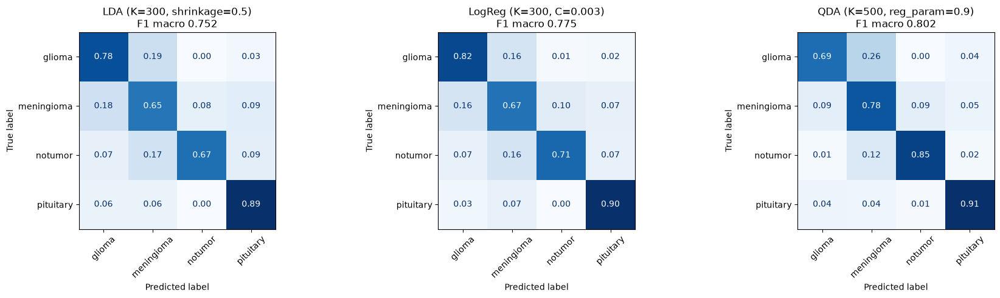

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

def crear_desde(fila):
    # Recupera el valor del hiperparámetro a partir del texto de "param" (p. ej. "reg_param=0.9")
    nombre_p, valores, crear = rejilla[fila.modelo]
    v = next(v for v in valores if f"{nombre_p}={v}" == fila.param)
    return crear(v)

finalistas = {f"{f.modelo} (K={f.K}, {f.param})": (f.K, crear_desde(f))
              for f in mejores_e1.itertuples()}

fig, axes = plt.subplots(1, len(finalistas), figsize=(6 * len(finalistas), 5))
for ax, (nombre, (K, clf)) in zip(np.atleast_1d(axes), finalistas.items()):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clf.fit(Z_train[:, :K], y_train)
    pred = clf.predict(Z_val[:, :K])
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, display_labels=clases, normalize="true",
        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{nombre}\nF1 macro {f1_score(y_val, pred, average='macro'):.3f}")
    ax.tick_params(axis="x", rotation=45)
    print(f"\n=== {nombre}")
    print(classification_report(y_val, pred, target_names=clases, digits=3))
plt.tight_layout(); plt.show()

### Ganador QDA:

Se puede observar que el ganador es QDA con una pequeña ventaja sobre LogReg. La matriz de confusión muestra que que la clase más complicada de predecir para estos modelos es "meningioma".

La clase más fácil de predecir es "pituitary", esto tiene sentido ya que este tipo de tumor aparece en una localización concreta del cerebro.  

# E2 CNN desde cero

El siguiente experimento intenta construir una CNN desde cero que sea capaz de competir con modelos preentrenados de clasificación de imágenes, haciendo uso de un menor número de parámetros.

En E1 vimos que los modelos clásicos no son capaces de aprovechar la estructura espacial de la imagen al tratar cada píxel como una variable. Por eso las redes neuronales convulucionales son capaces de obtener mejores resultados, las CNN son capaces de reconocer la estructura espacial de las imágenes detectando patrones, como el borde del cerebro. 

**Arquitectura.**
- 5 bloques Conv 3x3 -> BatchNorm -> ReLU -> MaxPool 2x2. Cada bloque duplica los canales (48 -> 768) y reduce a la mitad la resolución (224x224 -> 7x7). Las convoluciones no llevan sesgo porque la BatchNorm que las sigue ya incluye uno.
- Cabeza: *global average pooling* (un valor por canal, 768 en total), Dropout 0,3 y una capa lineal a las 4 clases.
- 3,5 M parámetros en total.

In [27]:
class CNN(nn.Module):
    def __init__(self, n_clases=4, base=48):
        super().__init__()
        def bloque(entrada, salida):
            return nn.Sequential(
                nn.Conv2d(entrada, salida, 3, padding=1, bias=False),
                nn.BatchNorm2d(salida),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(
            bloque(1, base),
            bloque(base, base*2),
            bloque(base*2, base*4),
            bloque(base*4,base*8),
            bloque(base*8, base*16)
        )
        
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(base*16, n_clases))

    def forward(self, x):
        return self.head(self.features(x))

model = CNN().to(DEVICE)
print(model)
print(f"\n{sum(p.numel() for p in model.parameters()):,} parámetros")

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(48, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, d

In [28]:
from torchinfo import summary
summary(model, input_size=(32, 1, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 4]                   --
├─Sequential: 1-1                        [32, 768, 7, 7]           --
│    └─Sequential: 2-1                   [32, 48, 112, 112]        --
│    │    └─Conv2d: 3-1                  [32, 48, 224, 224]        432
│    │    └─BatchNorm2d: 3-2             [32, 48, 224, 224]        96
│    │    └─ReLU: 3-3                    [32, 48, 224, 224]        --
│    │    └─MaxPool2d: 3-4               [32, 48, 112, 112]        --
│    └─Sequential: 2-2                   [32, 96, 56, 56]          --
│    │    └─Conv2d: 3-5                  [32, 96, 112, 112]        41,472
│    │    └─BatchNorm2d: 3-6             [32, 96, 112, 112]        192
│    │    └─ReLU: 3-7                    [32, 96, 112, 112]        --
│    │    └─MaxPool2d: 3-8               [32, 96, 56, 56]          --
│    └─Sequential: 2-3                   [32, 192, 28, 28]         --
│    │   

Definimos la misma transformación de las imágenes para la CNN. 

In [29]:
from torch.utils.data import Dataset, DataLoader

class MRIDataset(Dataset):
    def __init__(self, split, transform):
        sub = pd.read_csv("splits.csv").query("split == @split")
        self.rutas = sub["ruta"].to_numpy()
        self.y = sub["clase"].map(clase_a_idx).to_numpy()
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("L")
        return self.transform(img), int(self.y[i])

base_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
])

ds = {s: MRIDataset(s, base_tf) for s in ("train", "val", "test")}
loader = {s: DataLoader(ds[s], batch_size=32, shuffle=(s == "train"), num_workers=6)
          for s in ds}

X, y = next(iter(loader["train"]))
print(X.shape, X.dtype, X.min().item(), X.max().item(), y[:8])

torch.Size([32, 1, 224, 224]) torch.float32 0.0 1.0 tensor([3, 0, 3, 1, 3, 2, 1, 1])


## Bucle de entrenamiento

- **Pérdida y optimizador:** entropía cruzada y AdamW con lr = 1e-3 y decaimiento de pesos por defecto.
- **Planificador coseno** (`CosineAnnealingLR`, práctica TL08): el lr baja de forma suave de 1e-3 a 0 a lo largo de las 60 épocas, con pasos grandes al principio para explorar y pequeños al final para afinar.
- **60 épocas, batch 32.** Tras cada época se evalúa en val (pérdida, acierto y F1 macro).
- **Nos quedamos con el modelo de la última época**, no con el de la mejor época en validación. Elegir la mejor época es usar val para seleccionar el modelo, y su F1 sobrestima el rendimiento real porque en parte es fruto del azar. Con la última época, el F1 de val no tiene ese sesgo de selección.
- **3 semillas** por configuración, de las que damos la media. Con una sola ejecución no podríamos distinguir una mejora real de la variabilidad debida a la inicialización y al orden de los batches.

In [30]:
from sklearn.metrics import f1_score

def evaluar(model, loader, loss_fn):
    model.eval()
    perdida, y_true, y_pred = 0.0, [], []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            out = model(X)
            perdida += loss_fn(out, y).item() * len(y)
            y_pred.append(out.argmax(1).cpu()); y_true.append(y.cpu())
    y_true, y_pred = torch.cat(y_true), torch.cat(y_pred)
    return (perdida / len(y_true),
            (y_true == y_pred).float().mean().item(),
            f1_score(y_true, y_pred, average="macro"))

def entrenar(model, epocas=30, lr=1e-3, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epocas)

    hist= []
    for ep in range(epocas):
        model.train()
        perdida, aciertos, n = 0.0, 0, 0
        for X, y in loader["train"]:
            X, y = X.to(DEVICE), y.to(DEVICE)
            out = model(X)
            l = loss_fn(out, y)
            l.backward(); opt.step(); opt.zero_grad()
            perdida += l.item() * len(y); aciertos += (out.argmax(1) == y).sum().item(); n += len(y)
        sched.step()

        vl, va, vf1 = evaluar(model, loader["val"], loss_fn)
        hist.append({"epoca": ep, "tr_loss": perdida/n, "tr_acc": aciertos/n,
                     "val_loss": vl, "val_acc": va, "val_f1": vf1,
                     "lr": sched.get_last_lr()[0]})
        if verbose:
            print(f"ep {ep:2d}: train loss {perdida/n:.4f} acc {aciertos/n:.4f} | "
                  f"val loss {vl:.4f} acc {va:.4f} f1 {vf1:.4f}")

    return pd.DataFrame(hist), vf1

In [31]:
epochs = 60
torch.manual_seed(SEED)
model = CNN().to(DEVICE)

t0 = time.time()
hist, mejor_f1 = entrenar(model, epocas=epochs)
print(f"\nF1 macro en val: {mejor_f1:.4f} | {(time.time()-t0)/epochs:.1f} s/época")

ep  0: train loss 0.7709 acc 0.6968 | val loss 0.8846 acc 0.6247 f1 0.5758
ep  1: train loss 0.5764 acc 0.7793 | val loss 0.6395 acc 0.7649 f1 0.7560
ep  2: train loss 0.4912 acc 0.8155 | val loss 0.9222 acc 0.5865 f1 0.5484
ep  3: train loss 0.4531 acc 0.8299 | val loss 3.3339 acc 0.4224 f1 0.3015
ep  4: train loss 0.4128 acc 0.8484 | val loss 0.8194 acc 0.7152 f1 0.7428
ep  5: train loss 0.3693 acc 0.8561 | val loss 0.5475 acc 0.7853 f1 0.7904
ep  6: train loss 0.3345 acc 0.8728 | val loss 0.9845 acc 0.6380 f1 0.6698
ep  7: train loss 0.3185 acc 0.8782 | val loss 0.4435 acc 0.8350 f1 0.8331
ep  8: train loss 0.2954 acc 0.8882 | val loss 0.7654 acc 0.7161 f1 0.6855
ep  9: train loss 0.2952 acc 0.8864 | val loss 0.5191 acc 0.8066 f1 0.8082
ep 10: train loss 0.2790 acc 0.8918 | val loss 4.2928 acc 0.2609 f1 0.2155
ep 11: train loss 0.2243 acc 0.9170 | val loss 0.5338 acc 0.7817 f1 0.7822
ep 12: train loss 0.2103 acc 0.9247 | val loss 0.8468 acc 0.7551 f1 0.7165
ep 13: train loss 0.2114 

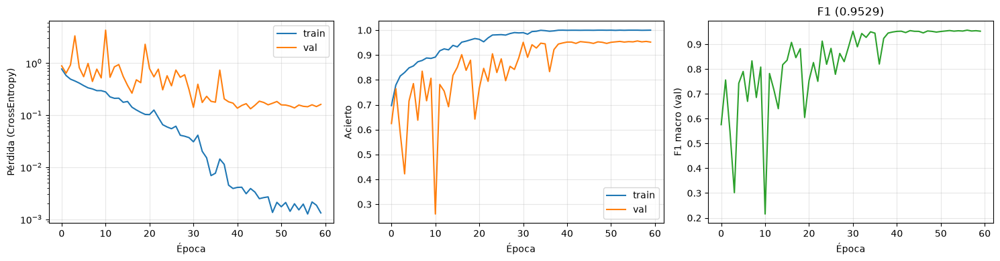

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist["epoca"], hist["tr_loss"], label="train")
axes[0].plot(hist["epoca"], hist["val_loss"], label="val")
axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")

axes[1].plot(hist["epoca"], hist["tr_acc"], label="train")
axes[1].plot(hist["epoca"], hist["val_acc"], label="val")
axes[1].set_ylabel("Acierto")

axes[2].plot(hist["epoca"], hist["val_f1"], color="tab:green")
axes[2].set_ylabel("F1 macro (val)")

for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
axes[2].set_title(f"F1 ({hist['val_f1'].iloc[-1]:.4f})")
plt.tight_layout(); plt.show()

Durante las primeras 30 épocas se puede observar que los resultados en validación oscilan de forma errática a pesar de que la perdida en train baja de forma suave. Para intentar mitigar esto se probaron diferentes schedulers, con y sin warmup e incluso diferentes tamaños de batch pero no desaparecen. A pesar de esto, el F1 macro al final del entrenamiento es muy elevado, alcanzando un valor de 0.9529 por lo que no se le da demasiada importancia a este comportamiento errático durante las primeras épocas.

Al final, la pérdida de train baja hasta ~$10^{-3}$ con un 100 % de acierto: la red memoriza el conjunto de entrenamiento. La pérdida de validación, en cambio, se estanca en torno a 0,15. No llega a subir, así que el rendimiento en val no se degrada, pero la diferencia indica que la red tiene capacidad de sobra para los datos disponibles. Ese margen es el que intentaremos reducir con el aumento de datos en E4.

In [33]:
resultados, modelos_e2 = [], []
t0 = time.time()
for s in (0, 1, 2):
    torch.manual_seed(SEED + s)
    m = CNN().to(DEVICE)
    h, f1 = entrenar(m, epocas=60, verbose=False)
    h["semilla"] = s
    resultados.append(h)
    modelos_e2. append(m)
    torch.save(m.state_dict(), f"results/e2_semilla{s}.pt")
    print(f"semilla {s}: F1 = {f1:.4f}")

hist_e2 = pd.concat(resultados, ignore_index=True)
hist_e2.to_csv("results/e2_scratch.csv", index=False)
mejores = hist_e2.groupby("semilla")["val_f1"].last()
print(f"\nE2: {mejores.mean():.4f} \nTiempo: {(time.time() - t0)/60:2} mins")

semilla 0: F1 = 0.9589
semilla 1: F1 = 0.9563
semilla 2: F1 = 0.9508

E2: 0.9553 
Tiempo: 11.564990695317586 mins


In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def predecir(model, loader):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for X, y in loader:
            yp.append(model(X.to(DEVICE)).argmax(1).cpu()); yt.append(y)
    return torch.cat(yt).numpy(), torch.cat(yp).numpy()

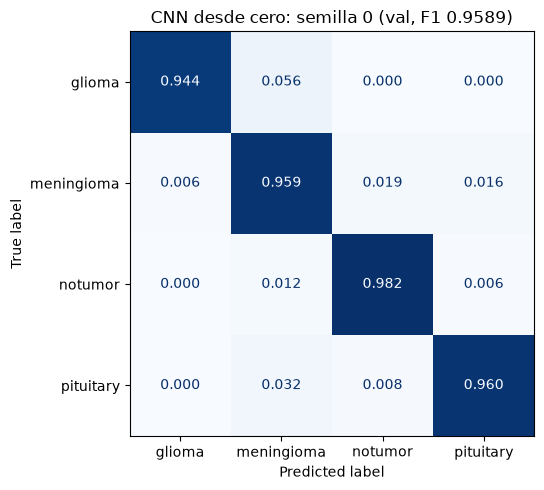

              precision    recall  f1-score   support

      glioma      0.995     0.944     0.968       390
  meningioma      0.905     0.959     0.932       319
     notumor      0.954     0.982     0.968       168
   pituitary      0.976     0.960     0.968       250

    accuracy                          0.957      1127
   macro avg      0.957     0.961     0.959      1127
weighted avg      0.959     0.957     0.958      1127



In [35]:
mejor_s = int(hist_e2.groupby("semilla")["val_f1"].last().idxmax())
yt, yp = predecir(modelos_e2[mejor_s], loader["val"])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yt, yp, display_labels=clases, normalize="true",
    values_format=".3f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"CNN desde cero: semilla {mejor_s} "
             f"(val, F1 {f1_score(yt, yp, average='macro'):.4f})")
plt.tight_layout(); plt.show()

print(classification_report(yt, yp, target_names=clases, digits=3))

## Conclusiones E2

- La CNN obtiene un F1 macro en val de **0,955** (3 semillas), frente a 0,802 del mejor modelo de E1: una mejora de unos 15 puntos. La variabilidad entre semillas es muy pequeña comparada con esa diferencia, así que la mejora es real demostrando que la capacidad de la CNN para explorar la estructura de las imágenes aporta considerablemente al resultado final.
- En la matriz de confusión podemos observar claramente que la clase más difícil de predecir es "meningioma".
- La CNN desarrollada es capaz memorizar el training data set mientras que la pérdida en val se estanca, por esta razón es normal pensar que el margen de mejora para la red se encuentra en la generalización, por lo que el estudio de la aplicación de técnicas como el aumento de datos gana aún más fuerza.


# E3. Modelo Preentrenado

La CNN llega a tener un 100% de acierto en train, con casi 4000 imágenes entrenar desde cero una CNN es capaz de memorizar el dataset sin problema. Una opción es utilizar modelos preentrenados y hacerles fine-tunning para que funcionen con nuestro problema.

Se utiliza ResNet18 preentrenada en ImageNet y se realizan 3 entrenamientos diferentes:
1. Entrenamos la capa de salida congelando el modelo completo, para comprobar hasta que punto las características de ImageNet sin ninguna adaptación son trasladables a esta tarea.
2. Fine-tunning del modelo completo.
3. Layer4: congelamos el modelo completo excepto el último bloque y la capa de salida.

In [36]:
model_e3 = timm.create_model("resnet18", pretrained=True, num_classes=4)
for p in model_e3.parameters():
    p.requires_grad = False
for p in model_e3.get_classifier().parameters():
    p.requires_grad = True
model_e3 = model_e3.to(DEVICE)

print(model_e3.get_classifier())
print(sum(p.numel() for p in model_e3.parameters() if p.requires_grad), "parámetros entrenables")

Linear(in_features=512, out_features=4, bias=True)
2052 parámetros entrenables


In [37]:
# data load
class MRIDatasetRGB(MRIDataset):
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("RGB")
        return self.transform(img), int(self.y[i])

In [38]:
data_cfg = timm.data.resolve_data_config(model_e3.pretrained_cfg)
transform = timm.data.create_transform(**data_cfg)
print(transform)

class MRIDatasetRGB(MRIDataset):
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("RGB")
        return self.transform(img), int(self.y[i])

train_loader = DataLoader(MRIDatasetRGB("train", transform), batch_size=32, shuffle=True,  num_workers=6)
val_loader   = DataLoader(MRIDatasetRGB("val",   transform), batch_size=32, shuffle=False, num_workers=6)

Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


In [39]:
def exp(model, device, train_loader, test_loader, lr=1e-3, epochs=15, verbose=True):
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    hist, best_acc = [], 0                      
    for epoch in range(epochs):
        if verbose: print(f'Epoch {epoch}: train:', end=' ')
        model.train(); trsize, trbatches, trloss, tracc = 0, 0, 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device); trsize += len(X); trbatches += 1
            pred = model(X); loss = loss_fn(pred, y); trloss += loss.item()
            tracc += (pred.argmax(1) == y).type(torch.float).sum().item()
            loss.backward(); optimizer.step(); optimizer.zero_grad()
        trloss /= trbatches; tracc /= trsize
        if verbose: print(f'loss {trloss:g} acc {tracc:.2%} val:', end=' ')
        sched.step()
        model.eval(); tesize, tebatches, teloss, teacc = 0, 0, 0, 0
        yt, yp = [], []
        with torch.no_grad():
            for X, y in test_loader:
                X, y = X.to(device), y.to(device); tesize += len(X); tebatches += 1
                pred = model(X); teloss += loss_fn(pred, y).item()
                teacc += (pred.argmax(1) == y).type(torch.float).sum().item()
                yt.append(y.cpu()); yp.append(pred.argmax(1).cpu())
        teloss /= tebatches; teacc /= tesize
        f1 = f1_score(torch.cat(yt), torch.cat(yp), average="macro")
        hist.append({"epoca": epoch, "tr_loss": trloss, "tr_acc": tracc,
                     "val_loss": teloss, "val_acc": teacc, "val_f1": f1}) 
        if teacc > best_acc:
            best_acc = teacc
        if verbose: print(f'loss {teloss:g} acc {teacc:.2%} f1 {f1:.4f}')
    return pd.DataFrame(hist), f1

### E3a. Linear probing

Se congelan todas las capas y solo se entrena la capa final: la ResNet actúa como un extractor de características fijo y encima se ajusta un clasificador lineal. Mide hasta qué punto las características de ImageNet, sin ninguna adaptación, separan las clases.

In [40]:
torch.manual_seed(SEED)
epo = 60
t0 = time.time()
hist, mejor_f1 = exp(model_e3, DEVICE, train_loader, val_loader, lr=1e-3, epochs=epo)
print(f"\nF1 macro en val: {mejor_f1:.4f} | {(time.time()-t0)/epo:.1f} s/época")

Epoch 0: train: loss 1.02523 acc 65.88% val: loss 0.802888 acc 80.66% f1 0.8188
Epoch 1: train: loss 0.697061 acc 79.91% val: loss 0.611102 acc 82.43% f1 0.8319
Epoch 2: train: loss 0.595738 acc 80.42% val: loss 0.545557 acc 82.70% f1 0.8315
Epoch 3: train: loss 0.534358 acc 82.19% val: loss 0.495789 acc 84.47% f1 0.8517
Epoch 4: train: loss 0.49695 acc 83.32% val: loss 0.463744 acc 84.38% f1 0.8496
Epoch 5: train: loss 0.472793 acc 84.15% val: loss 0.44423 acc 84.92% f1 0.8501
Epoch 6: train: loss 0.445886 acc 84.74% val: loss 0.420947 acc 85.45% f1 0.8593
Epoch 7: train: loss 0.43625 acc 85.25% val: loss 0.412693 acc 86.60% f1 0.8701
Epoch 8: train: loss 0.417981 acc 85.79% val: loss 0.395558 acc 86.25% f1 0.8658
Epoch 9: train: loss 0.409344 acc 85.92% val: loss 0.39336 acc 87.40% f1 0.8785
Epoch 10: train: loss 0.397232 acc 86.54% val: loss 0.380307 acc 86.51% f1 0.8669
Epoch 11: train: loss 0.382689 acc 87.05% val: loss 0.380305 acc 87.58% f1 0.8803
Epoch 12: train: loss 0.373284 

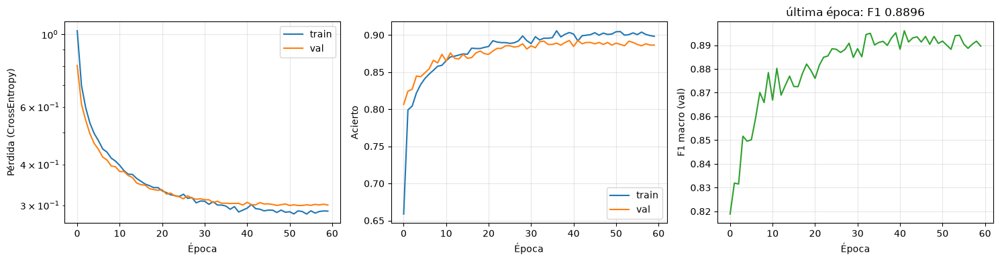

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist["epoca"], hist["tr_loss"], label="train")
axes[0].plot(hist["epoca"], hist["val_loss"], label="val")
axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")

axes[1].plot(hist["epoca"], hist["tr_acc"], label="train")
axes[1].plot(hist["epoca"], hist["val_acc"], label="val")
axes[1].set_ylabel("Acierto")

axes[2].plot(hist["epoca"], hist["val_f1"], color="tab:green")
axes[2].set_ylabel("F1 macro (val)")

for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
axes[2].set_title(f"última época: F1 {hist['val_f1'].iloc[-1]:.4f}")
plt.tight_layout(); plt.show()

In [42]:
resultados, modelos_e3 = [], []
t0 = time.time()
for s in (0, 1, 2):
    torch.manual_seed(SEED + s)
    model_e3 = timm.create_model("resnet18", pretrained=True, num_classes=4)
    for p in model_e3.parameters():
        p.requires_grad = False
    for p in model_e3.get_classifier().parameters():
        p.requires_grad = True
    model_e3 = model_e3.to(DEVICE)
    h, f1 = exp(model_e3, DEVICE, train_loader, val_loader, lr=1e-3, epochs=60, verbose=False)
    h["semilla"] = s
    resultados.append(h)
    modelos_e3. append(model_e3)
    torch.save(model_e3.state_dict(), f"results/e3_semilla{s}.pt")
    print(f"semilla {s}: F1 = {f1:.4f}")

hist_e3 = pd.concat(resultados, ignore_index=True)
hist_e3.to_csv("results/e3_scratch.csv", index=False)
mejores = hist_e3.groupby("semilla")["val_f1"].last()
print(f"\nE3a: {mejores.mean():.4f} \nTiempo: {(time.time() - t0)/60:2} mins")

<>:21: SyntaxWarning: invalid escape sequence '\E'
<>:21: SyntaxWarning: invalid escape sequence '\E'
/tmp/ipykernel_26673/4202827747.py:21: SyntaxWarning: invalid escape sequence '\E'
  print(f"\E3a: {mejores.mean():.4f} \nTiempo: {(time.time() - t0)/60:2} mins")


semilla 0: F1 = 0.8955
semilla 1: F1 = 0.8987
semilla 2: F1 = 0.8917
\E3a: 0.8953 
Tiempo: 6.0667305072148645 mins


El *linear probing* obtiene un F1 macro en val de **0,8953**, por debajo de la CNN desde cero (0,955). Las curvas de train y val van prácticamente superpuestas y no hay sobreajuste, sino lo contrario. El modelo no consigue ajustar ni siquiera los datos de entrenamiento, así que el límite está en la representación: las características de ImageNet, tal cual, no son lo bastante discriminativas para distinguir los tipos de tumor con una frontera lineal.

### E3b. Fine-tuning completo

Se entrenan todas las capas de la red partiendo de los pesos de ImageNet, que funcionan como inicialización en lugar de pesos aleatorios.

In [43]:
# modelo completo
model_e3_entero = timm.create_model("resnet18", pretrained=True, num_classes=4)
model_e3_entero = model_e3_entero.to(DEVICE)

print(model_e3_entero.get_classifier())
print(sum(p.numel() for p in model_e3_entero.parameters() if p.requires_grad), "parametros entrenables.")

Linear(in_features=512, out_features=4, bias=True)
11178564 parametros entrenables.


In [44]:
data_cfg = timm.data.resolve_data_config(model_e3_entero.pretrained_cfg)
transform = timm.data.create_transform(**data_cfg)
print(transform)

train_loader = DataLoader(MRIDatasetRGB("train", transform), batch_size=32, shuffle=True,  num_workers=6)
val_loader   = DataLoader(MRIDatasetRGB("val",   transform), batch_size=32, shuffle=False, num_workers=6)

Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


In [45]:
torch.manual_seed(SEED)
epo = 60
t0 = time.time()
hist_todo, mejor_f1_todo = exp(model_e3_entero, DEVICE, train_loader, val_loader, lr=1e-3, epochs=epo)
print(f"\nF1 macro en val: {mejor_f1_todo:.4f} | {(time.time()-t0)/epo:.1f} s/época")

Epoch 0: train: loss 0.369714 acc 87.02% val: loss 0.177763 acc 94.41% f1 0.9426
Epoch 1: train: loss 0.106824 acc 96.09% val: loss 0.100627 acc 96.45% f1 0.9663
Epoch 2: train: loss 0.073911 acc 97.43% val: loss 0.21871 acc 92.10% f1 0.9257
Epoch 3: train: loss 0.0477658 acc 98.30% val: loss 0.0778273 acc 97.60% f1 0.9782
Epoch 4: train: loss 0.0260904 acc 99.23% val: loss 0.0897875 acc 96.98% f1 0.9706
Epoch 5: train: loss 0.0288203 acc 99.15% val: loss 0.148212 acc 95.21% f1 0.9545
Epoch 6: train: loss 0.0241699 acc 99.36% val: loss 0.0894488 acc 96.63% f1 0.9699
Epoch 7: train: loss 0.00816318 acc 99.77% val: loss 0.112654 acc 95.21% f1 0.9557
Epoch 8: train: loss 0.0077175 acc 99.77% val: loss 0.378871 acc 88.11% f1 0.8597
Epoch 9: train: loss 0.0157615 acc 99.41% val: loss 0.0977475 acc 96.63% f1 0.9667
Epoch 10: train: loss 0.031847 acc 98.95% val: loss 0.0835837 acc 96.63% f1 0.9680
Epoch 11: train: loss 0.00702581 acc 99.87% val: loss 0.0608658 acc 98.05% f1 0.9810
Epoch 12: t

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist_todo["epoca"], hist_todo["tr_loss"], label="train")
axes[0].plot(hist_todo["epoca"], hist_todo["val_loss"], label="val")
axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")
MRIDataset
axes[1].plot(hist_todo["epoca"], hist_todo["tr_acc"], label="train")
axes[1].plot(hist_todo["epoca"], hist_todo["val_acc"], label="val")
axes[1].set_ylabel("Acierto")

axes[2].plot(hist_todo["epoca"], hist_todo["val_f1"], color="tab:green")
axes[2].set_ylabel("F1 macro (val)")

for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
axes[2].set_title(f"F1 ({hist_todo['val_f1'].iloc[-1]:.4f})")
plt.tight_layout(); plt.show()

In [46]:
resultados, modelos_e3_entero = [], []
t0 = time.time()
for s in (0, 1, 2):
    torch.manual_seed(SEED + s)
    model_e3_entero = timm.create_model("resnet18", pretrained=True, num_classes=4)
    model_e3_entero = model_e3_entero.to(DEVICE)
    h, f1 = exp(model_e3_entero, DEVICE, train_loader, val_loader, lr=1e-3, epochs=60, verbose=False)
    h["semilla"] = s
    resultados.append(h)
    modelos_e3_entero.append(model_e3_entero)
    torch.save(model_e3_entero.state_dict(), f"results/e3_entero_semilla{s}.pt")
    print(f"semilla {s}: F1 = {f1:.4f}")

hist_e3_entero = pd.concat(resultados, ignore_index=True)
hist_e3_entero.to_csv("results/e3_entero_scratch.csv", index=False)
mejores = hist_e3_entero.groupby("semilla")["val_f1"].last()
print(f"\nE3b: {mejores.mean():.4f}\nTiempo: {(time.time() - t0)/60:2} mins")

semilla 0: F1 = 0.9763
semilla 1: F1 = 0.9821
semilla 2: F1 = 0.9852

E3b: 0.9812
Tiempo: 8.93087034225464 mins


In [47]:
torch.save(model_e3_entero.state_dict(), "results/e3_entero.pt")
hist_todo.to_csv("results/e3_todo.csv", index=False)

El *fine-tuning* completo sube a **0,981** en val, la mejor configuración hasta ahora y 2,6 puntos por encima de la CNN desde cero con los mismos datos. La red llega al 100 % de acierto en train en pocas épocas y la pérdida de train baja a ~$10^{-5}$, mientras que la de val se estabiliza en torno a 0,06: también memoriza el conjunto de entrenamiento, pero partiendo de mejores pesos generaliza mejor.

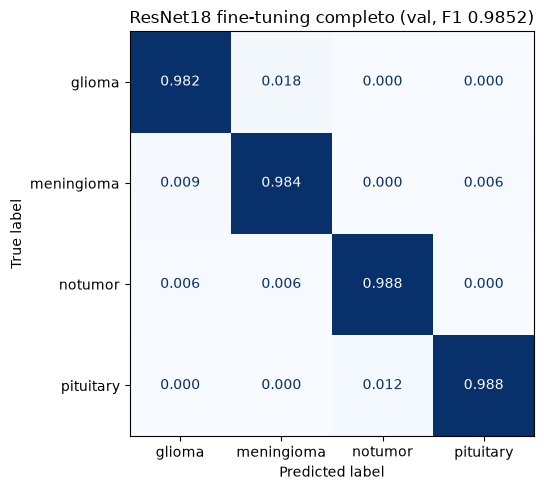

              precision    recall  f1-score   support

      glioma      0.990     0.982     0.986       390
  meningioma      0.975     0.984     0.980       319
     notumor      0.982     0.988     0.985       168
   pituitary      0.992     0.988     0.990       250

    accuracy                          0.985      1127
   macro avg      0.985     0.986     0.985      1127
weighted avg      0.985     0.985     0.985      1127



In [48]:
def predecir(model, loader):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for X, y in loader:
            yp.append(model(X.to(DEVICE)).argmax(1).cpu()); yt.append(y)
    return torch.cat(yt).numpy(), torch.cat(yp).numpy()

yt, yp = predecir(model_e3_entero, val_loader)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yt, yp, display_labels=clases, normalize="true",
    values_format=".3f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"ResNet18 fine-tuning completo (val, F1 {f1_score(yt, yp, average='macro'):.4f})")
plt.tight_layout(); plt.show()

print(classification_report(yt, yp, target_names=clases, digits=3))

### E3c. Fine-tuning de layer4 + cabeza

Variante intermedia: se congelan todas las capas salvo el último bloque residual (`layer4`) y la capa final. La idea es conservar los detectores de bajo nivel de ImageNet y adaptar solo las características de más alto nivel.

In [49]:
torch.manual_seed(SEED)
model_e3_l4 = timm.create_model("resnet18", pretrained=True, num_classes=4)

for p in model_e3_l4.parameters():
    p.requires_grad = False
for modulo  in (model_e3_l4.layer4, model_e3_l4.get_classifier()):
    for p in modulo.parameters():
        p.requires_grad = True
model_e3_l4 = model_e3_l4.to(DEVICE)


print(sum(p.numel() for p in model_e3_l4.parameters() if p.requires_grad), "parámetros entrenables")

8395780 parámetros entrenables


In [50]:
epo = 60
t0 = time.time()
hist_l4, mejor_f1_l4 = exp(model_e3_l4, DEVICE, train_loader, val_loader, lr=1e-3, epochs=epo)
print(f"\nF1 macro en val: {mejor_f1_l4:.4f} | {(time.time()-t0)/epo:.1f} s/época")

torch.save(model_e3_l4.state_dict(), "results/e3_layer4.pt")
hist_l4.to_csv("results/e3_layer4.csv", index=False)

Epoch 0: train: loss 0.461441 acc 83.25% val: loss 0.231138 acc 90.59% f1 0.9082
Epoch 1: train: loss 0.121478 acc 95.81% val: loss 0.230371 acc 92.72% f1 0.9327
Epoch 2: train: loss 0.0376825 acc 99.05% val: loss 0.138858 acc 94.76% f1 0.9476
Epoch 3: train: loss 0.0295071 acc 99.02% val: loss 0.134154 acc 95.39% f1 0.9550
Epoch 4: train: loss 0.0168391 acc 99.51% val: loss 0.16099 acc 95.03% f1 0.9503
Epoch 5: train: loss 0.0192324 acc 99.41% val: loss 0.163683 acc 95.12% f1 0.9535
Epoch 6: train: loss 0.0262437 acc 99.15% val: loss 0.154904 acc 95.39% f1 0.9532
Epoch 7: train: loss 0.00749114 acc 99.82% val: loss 0.172941 acc 94.76% f1 0.9480
Epoch 8: train: loss 0.00288436 acc 99.97% val: loss 0.16806 acc 94.94% f1 0.9502
Epoch 9: train: loss 0.00312707 acc 99.92% val: loss 0.171845 acc 95.12% f1 0.9523
Epoch 10: train: loss 0.00920591 acc 99.69% val: loss 0.263137 acc 93.70% f1 0.9406
Epoch 11: train: loss 0.00624163 acc 99.87% val: loss 0.161486 acc 95.21% f1 0.9535
Epoch 12: tra

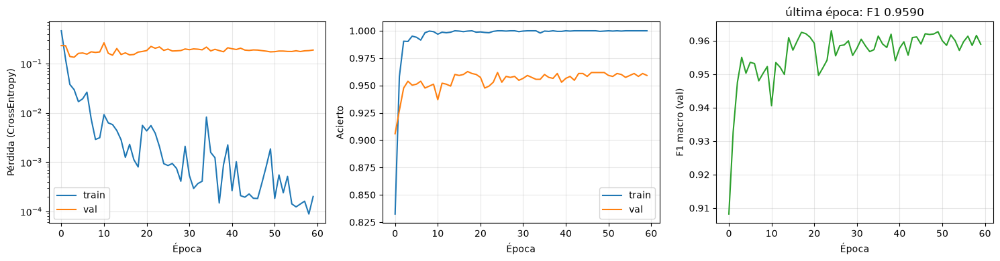

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist_l4["epoca"], hist_l4["tr_loss"], label="train")
axes[0].plot(hist_l4["epoca"], hist_l4["val_loss"], label="val")
axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")

axes[1].plot(hist_l4["epoca"], hist_l4["tr_acc"], label="train")
axes[1].plot(hist_l4["epoca"], hist_l4["val_acc"], label="val")
axes[1].set_ylabel("Acierto")

axes[2].plot(hist_l4["epoca"], hist_l4["val_f1"], color="tab:green")
axes[2].set_ylabel("F1 macro (val)")

for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
axes[2].set_title(f"última época: F1 {hist_l4['val_f1'].iloc[-1]:.4f}")
plt.tight_layout(); plt.show()

In [52]:
resultados, modelos_e3_l4 = [], []
t0 = time.time()
for s in (0, 1, 2):
    torch.manual_seed(SEED + s)
    model_e3_l4 = timm.create_model("resnet18", pretrained=True, num_classes=4)

    for p in model_e3_l4.parameters():
        p.requires_grad = False
    for modulo  in (model_e3_l4.layer4, model_e3_l4.get_classifier()):
        for p in modulo.parameters():
            p.requires_grad = True
    model_e3_l4 = model_e3_l4.to(DEVICE)
    h, f1 = exp(model_e3_l4, DEVICE, train_loader, val_loader, lr=1e-3, epochs=60, verbose=False)
    h["semilla"] = s
    resultados.append(h)
    modelos_e3_l4. append(model_e3_l4)
    torch.save(model_e3_l4.state_dict(), f"results/e3_l4_semilla{s}.pt")
    print(f"semilla {s}: F1 = {f1:.4f}")

hist_e3_l4 = pd.concat(resultados, ignore_index=True)
hist_e3_l4.to_csv("results/e3_scratch_l4.csv", index=False)
mejores = hist_e3_l4.groupby("semilla")["val_f1"].last()
print(f"\nE3c: {mejores.mean():.4f} \nTiempo: {(time.time() - t0)/60:2} mins")

semilla 0: F1 = 0.9590
semilla 1: F1 = 0.9605
semilla 2: F1 = 0.9579

E3c: 0.9592 
Tiempo: 6.0885513663291935 mins


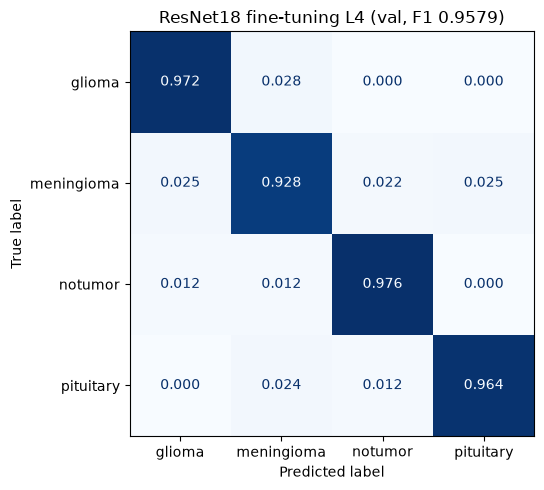

              precision    recall  f1-score   support

      glioma      0.974     0.972     0.973       390
  meningioma      0.940     0.928     0.934       319
     notumor      0.943     0.976     0.959       168
   pituitary      0.968     0.964     0.966       250

    accuracy                          0.958      1127
   macro avg      0.956     0.960     0.958      1127
weighted avg      0.958     0.958     0.958      1127



In [53]:
def predecir(model, loader):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for X, y in loader:
            yp.append(model(X.to(DEVICE)).argmax(1).cpu()); yt.append(y)
    return torch.cat(yt).numpy(), torch.cat(yp).numpy()

yt, yp = predecir(model_e3_l4, val_loader)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yt, yp, display_labels=clases, normalize="true",
    values_format=".3f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"ResNet18 fine-tuning L4 (val, F1 {f1_score(yt, yp, average='macro'):.4f})")
plt.tight_layout(); plt.show()

print(classification_report(yt, yp, target_names=clases, digits=3))

### Conclusiones E3

| Variante | F1 macro val |
|---|---|
| E3a | 0,895 |
| E3b | **0,981** |
| E3c | 0,959 |
| *(E2: CNN desde cero)* | *0,955* |

- Cuantas más capas se adaptan, mejor resultado. Las características de ImageNet sin adaptar no bastan (*linear probing* queda por debajo de la CNN desde cero), pero como punto de partida son mejores que una inicialización aleatoria.
- *layer4* entrena el 75 % de los parámetros y aun así queda 2 puntos por debajo del *fine-tuning* completo, y solo ligeramente por encima de E2. Además sobreajusta antes: 100 % en train desde la época ~14 con la pérdida de val estancada en ~0,18. Esto indica que también las primeras capas necesitan adaptarse: los detectores de bajo nivel aprendidos con fotografías en color no son los más adecuados para resonancias en escala de grises.
- Todas las variantes que entrenan capas convolucionales llegan al 100 % en train. Con la misma cantidad de datos, el preentrenamiento mejora la generalización pero no evita la memorización, lo que motiva probar el aumento de datos (E4).

# E4. Data augmentation

Prácticamente todos los modelos no tradicionales probados en este trabajo memorizan el training dataset alcanzando una precisión del 100%. Esto nos puede hacer pensar que el problema esta en la memorización de los datos, para esto el aumento de datos es una herramienta de gran valor en estos casos para mejorar la generalización de los modelos evitando que estos observen la misma imagen en repetidas ocasiones. 

Para probar esto la arquitectura y los parámetros de los modelos son exactamente igual que en sus respectivos experimentos, ya que el objetivo es observar como afecta el aumento de datos a la generalización de los mismo. 

La transformación aplicada es una trasnformación suave para generar variantes plausibles de una resonancia.


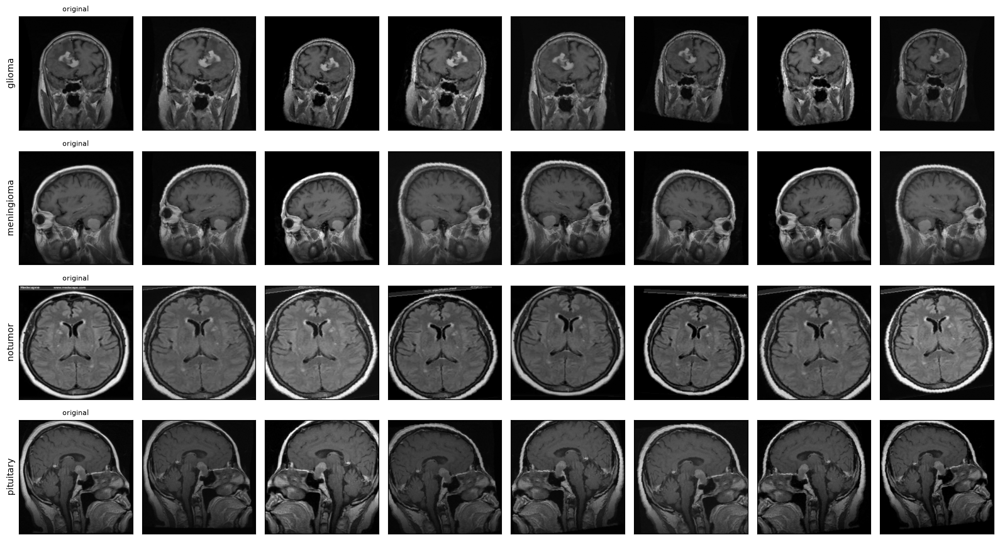

In [54]:
# transformación aplicada
aug_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.ToDtype(torch.float32, scale=True),
])

# Una imagen de train por clase: la original y 7 versiones aumentadas
tren = df[df["split"] == "train"]
fig, axes = plt.subplots(len(clases), 8, figsize=(16, 2.2 * len(clases)))
for i, clase in enumerate(clases):
    img = Image.open(tren.loc[tren["clase"] == clase, "ruta"].iloc[0]).convert("L")
    axes[i, 0].imshow(base_tf(img)[0], cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title("original", fontsize=8)
    for j in range(1, 8):
        axes[i, j].imshow(aug_tf(img)[0], cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_ylabel(clase)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### E4a. CNN desde cero con aumento de datos

In [55]:
# nuevo bucle de entrenamiento CNN con data augmentation
def entrenar_e4(model, epocas=30, lr=1e-3, verbose=True, loaders=loader):
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epocas)

    hist = []
    for ep in range(epocas):
        model.train()
        perdida, aciertos, n = 0.0, 0, 0
        for X, y in loaders["train"]:
            X, y = X.to(DEVICE), y.to(DEVICE)
            out = model(X)
            l = loss_fn(out, y)
            l.backward(); opt.step(); opt.zero_grad()
            perdida += l.item() * len(y); aciertos += (out.argmax(1) == y).sum().item(); n += len(y)
        sched.step()

        vl, va, vf1 = evaluar(model, loaders["val"], loss_fn)
        hist.append({"epoca": ep, "tr_loss": perdida/n, "tr_acc": aciertos/n,
                     "val_loss": vl, "val_acc": va, "val_f1": vf1,
                     "lr": sched.get_last_lr()[0]})
        if verbose:
            print(f"ep {ep:2d}: train loss {perdida/n:.4f} acc {aciertos/n:.4f} | "
                  f"val loss {vl:.4f} acc {va:.4f} f1 {vf1:.4f}")

    return pd.DataFrame(hist), vf1

In [56]:
loader_e4 = {"train": DataLoader(MRIDataset("train", aug_tf), batch_size=32, shuffle=True, num_workers=6),
             "val": loader["val"]}   # val con base_tf, igual que en E2

epochs = 60
torch.manual_seed(SEED)
model = CNN().to(DEVICE)

t0 = time.time()
hist_e4, mejor_f1 = entrenar_e4(model, epocas=epochs, loaders=loader_e4)
print(f"\nF1 macro en val: {mejor_f1:.4f} | {(time.time()-t0)/epochs:.1f} s/época")

ep  0: train loss 0.9357 acc 0.6077 | val loss 0.9924 acc 0.5812 f1 0.6045
ep  1: train loss 0.7904 acc 0.6804 | val loss 0.8134 acc 0.6380 f1 0.5773
ep  2: train loss 0.6721 acc 0.7356 | val loss 0.6157 acc 0.7436 f1 0.7289
ep  3: train loss 0.6191 acc 0.7626 | val loss 0.6949 acc 0.6761 f1 0.6785
ep  4: train loss 0.5479 acc 0.7901 | val loss 0.5052 acc 0.8279 f1 0.8326
ep  5: train loss 0.4873 acc 0.8140 | val loss 0.6249 acc 0.7356 f1 0.7296
ep  6: train loss 0.4677 acc 0.8222 | val loss 0.4737 acc 0.8314 f1 0.8414
ep  7: train loss 0.4375 acc 0.8371 | val loss 0.4154 acc 0.8465 f1 0.8489
ep  8: train loss 0.4327 acc 0.8404 | val loss 0.4484 acc 0.8367 f1 0.8433
ep  9: train loss 0.4239 acc 0.8453 | val loss 1.4659 acc 0.5785 f1 0.5733
ep 10: train loss 0.4044 acc 0.8520 | val loss 0.7358 acc 0.7382 f1 0.7186
ep 11: train loss 0.3459 acc 0.8769 | val loss 1.4643 acc 0.6327 f1 0.5714
ep 12: train loss 0.3791 acc 0.8672 | val loss 0.4790 acc 0.8146 f1 0.8235
ep 13: train loss 0.3535 

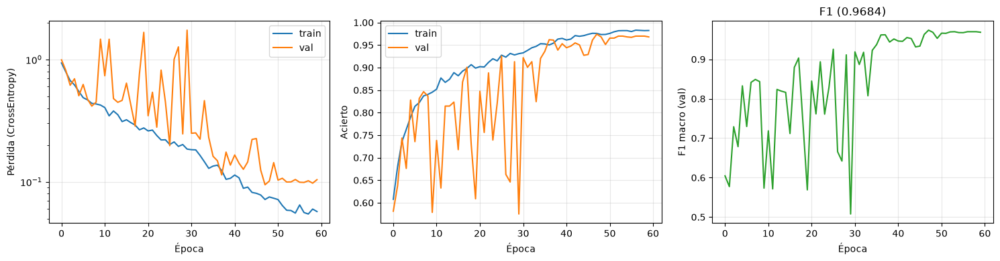

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist_e4["epoca"], hist_e4["tr_loss"], label="train")
axes[0].plot(hist_e4["epoca"], hist_e4["val_loss"], label="val")
axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")

axes[1].plot(hist_e4["epoca"], hist_e4["tr_acc"], label="train")
axes[1].plot(hist_e4["epoca"], hist_e4["val_acc"], label="val")
axes[1].set_ylabel("Acierto")

axes[2].plot(hist_e4["epoca"], hist_e4["val_f1"], color="tab:green")
axes[2].set_ylabel("F1 macro (val)")

for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].legend(); axes[1].legend()
axes[2].set_title(f"F1 ({hist_e4['val_f1'].iloc[-1]:.4f})")
plt.tight_layout(); plt.show()

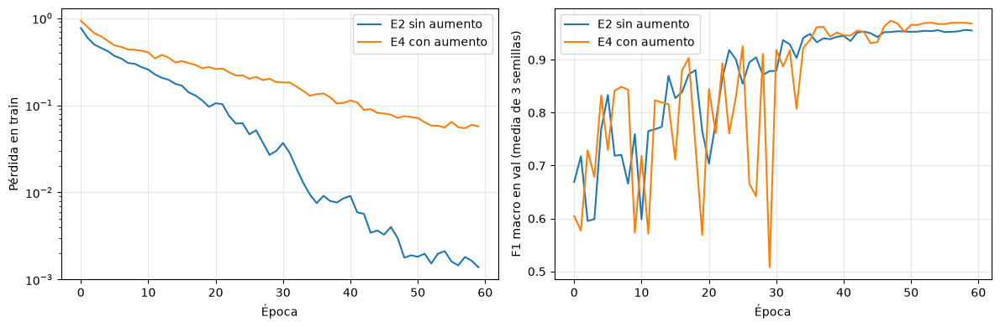

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, h in (("E2 sin aumento", hist_e2), ("E4 con aumento", hist_e4)):
    media = h.groupby("epoca")[["tr_loss", "val_f1"]].mean()
    axes[0].plot(media.index, media["tr_loss"], label=nombre)
    axes[1].plot(media.index, media["val_f1"], label=nombre)
axes[0].set_ylabel("Pérdida en train"); axes[0].set_yscale("log")
axes[1].set_ylabel("F1 macro en val (media de 3 semillas)")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [59]:
resultados, modelos_e4 = [], []
t0 = time.time()
for s in (0, 1, 2):
    torch.manual_seed(SEED + s)
    m = CNN().to(DEVICE)
    h, f1 = entrenar_e4(m, epocas=60, verbose=False, loaders=loader_e4)
    h["semilla"] = s
    resultados.append(h)
    modelos_e4.append(m)
    torch.save(m.state_dict(), f"results/e4_semilla{s}.pt")
    print(f"semilla {s}: F1 = {f1:.4f}")

hist_e4 = pd.concat(resultados, ignore_index=True)
hist_e4.to_csv("results/e4_cnn_aug.csv", index=False)

hist_e2 = pd.read_csv("results/e2_scratch.csv")
m2 = hist_e2.groupby("semilla")["val_f1"].last()
m4 = hist_e4.groupby("semilla")["val_f1"].last()
print(f"\nE2 (sin aumento): {m2.mean():.4f}")
print(f"E4 (con aumento): {m4.mean():.4f}")
print(f"Diferencia por semilla (E4 - E2): {(m4 - m2).round(4).to_dict()}")
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")

semilla 0: F1 = 0.9702
semilla 1: F1 = 0.9746
semilla 2: F1 = 0.9639

E2 (sin aumento): 0.9553
E4 (con aumento): 0.9696
Diferencia por semilla (E4 - E2): {0: 0.0113, 1: 0.0184, 2: 0.0131}
Tiempo: 11.7 min


Con aumento, la CNN pasa de **0,955** a **0,970** en val, y mejora con las tres semillas. Las curvas muestran el efecto regularizador: la pérdida de train ya no cae hasta ~$10^{-3}$, sino que se queda en ~0,05, con un ~98 % de acierto en train. La red ya no puede memorizar las imágenes y, a cambio, generaliza mejor.

### E4b. Aumento de datos en el fine-tuning de ResNet18

En este caso se ha tomado la decisión de no probar el aumento de datos para E3a (linear probing) ya que este modelo no mostraba signos de memorización de las imágenes ya que su porcentaje de aciertos se mantenía entre el 80% y el 90% durante toda la ejecución.

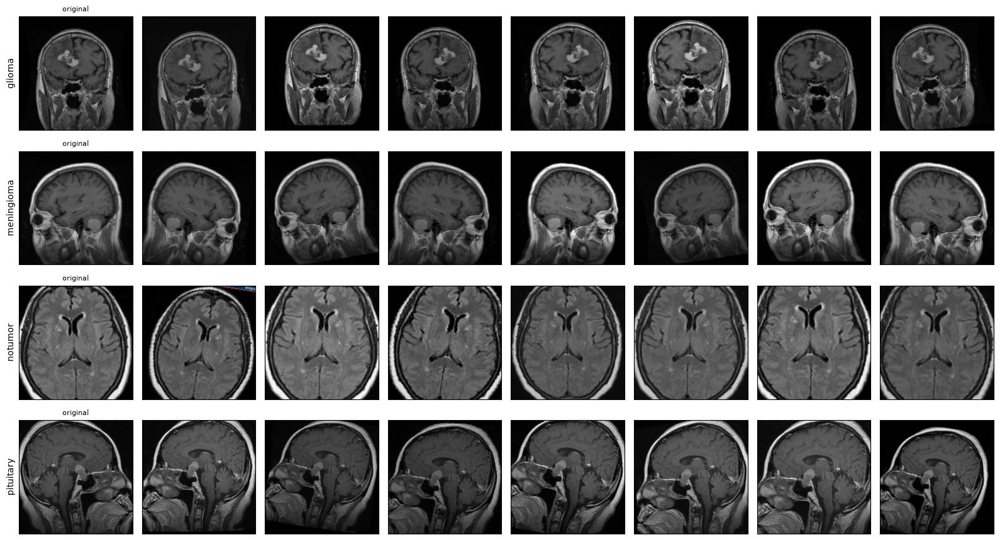

In [60]:
# Aumento sobre la imagen PIL original; después, la transformación de timm (resize 235, crop 224, normalización)
aug_tf_rgb = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    transform,
])

# Para dibujar hay que deshacer la normalización de ImageNet
media = torch.tensor(data_cfg["mean"]).view(3, 1, 1)
desv  = torch.tensor(data_cfg["std"]).view(3, 1, 1)
a_imagen = lambda x: (x * desv + media).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(len(clases), 8, figsize=(16, 2.2 * len(clases)))
for i, clase in enumerate(clases):
    img = Image.open(tren.loc[tren["clase"] == clase, "ruta"].iloc[0]).convert("RGB")
    axes[i, 0].imshow(a_imagen(transform(img)))
    axes[i, 0].set_title("original", fontsize=8)
    for j in range(1, 8):
        axes[i, j].imshow(a_imagen(aug_tf_rgb(img)))
    axes[i, 0].set_ylabel(clase)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

train_loader_aug = DataLoader(MRIDatasetRGB("train", aug_tf_rgb), batch_size=32, shuffle=True, num_workers=6)

In [61]:
def crear_resnet(solo_layer4):
    m = timm.create_model("resnet18", pretrained=True, num_classes=4)
    if solo_layer4:
        for p in m.parameters():
            p.requires_grad = False
        for modulo in (m.layer4, m.get_classifier()):
            for p in modulo.parameters():
                p.requires_grad = True
    return m.to(DEVICE)

configs = (("entero", False, "fine-tuning completo"), ("l4", True, "layer4 + cabeza"))
hist_aug = {}
for nombre, solo_l4, _ in configs:
    resultados, t0 = [], time.time()
    for s in (0, 1, 2):
        torch.manual_seed(SEED + s)
        m = crear_resnet(solo_l4)
        h, f1 = exp(m, DEVICE, train_loader_aug, val_loader, lr=1e-3, epochs=60, verbose=False)
        h["semilla"] = s
        resultados.append(h)
        torch.save(m.state_dict(), f"results/e4_{nombre}_semilla{s}.pt")
        print(f"{nombre}, semilla {s}: F1 = {f1:.4f}")
    hist_aug[nombre] = pd.concat(resultados, ignore_index=True)
    hist_aug[nombre].to_csv(f"results/e4_{nombre}_aug.csv", index=False)
    print(f"  {(time.time() - t0) / 60:.1f} min\n")

entero, semilla 0: F1 = 0.9855
entero, semilla 1: F1 = 0.9906
entero, semilla 2: F1 = 0.9922
  9.1 min

l4, semilla 0: F1 = 0.9749
l4, semilla 1: F1 = 0.9775
l4, semilla 2: F1 = 0.9713
  8.5 min



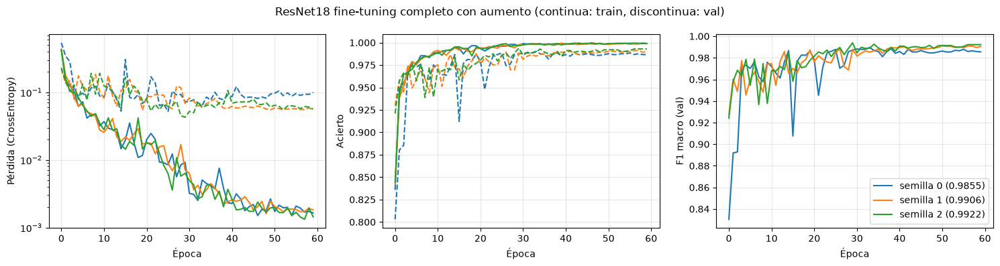

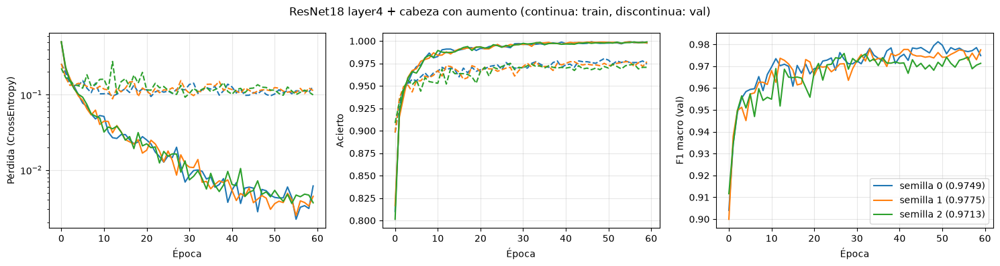

In [62]:
colores = ["tab:blue", "tab:orange", "tab:green"]
for nombre, _, titulo in configs:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for s, hs in hist_aug[nombre].groupby("semilla"):
        c = colores[s]
        axes[0].plot(hs["epoca"], hs["tr_loss"], c=c)
        axes[0].plot(hs["epoca"], hs["val_loss"], c=c, ls="--")
        axes[1].plot(hs["epoca"], hs["tr_acc"], c=c)
        axes[1].plot(hs["epoca"], hs["val_acc"], c=c, ls="--")
        axes[2].plot(hs["epoca"], hs["val_f1"], c=c, label=f"semilla {s} ({hs['val_f1'].iloc[-1]:.4f})")
    axes[0].set_ylabel("Pérdida (CrossEntropy)"); axes[0].set_yscale("log")
    axes[1].set_ylabel("Acierto")
    axes[2].set_ylabel("F1 macro (val)"); axes[2].legend()
    for ax in axes:
        ax.set_xlabel("Época"); ax.grid(alpha=0.3)
    fig.suptitle(f"ResNet18 {titulo} con aumento (continua: train, discontinua: val)")
    plt.tight_layout(); plt.show()

In [63]:
sin_aug = {"entero": pd.read_csv("results/e3_entero_scratch.csv"),
              "l4":     pd.read_csv("results/e3_scratch_l4.csv")}

for nombre, _, titulo in configs:
    a = sin_aug[nombre].groupby("semilla")["val_f1"].last()
    b = hist_aug[nombre].groupby("semilla")["val_f1"].last()
    print(f"{titulo}:\n  sin aumento {a.mean():.4f}\n"
            f"  con aumento {b.mean():.4f} \n"
            f"  diferencia por semilla (con - sin): {(b - a).round(4).to_dict()}")

fine-tuning completo:
  sin aumento 0.9812
  con aumento 0.9894 
  diferencia por semilla (con - sin): {0: 0.0092, 1: 0.0085, 2: 0.007}
layer4 + cabeza:
  sin aumento 0.9592
  con aumento 0.9745 
  diferencia por semilla (con - sin): {0: 0.0159, 1: 0.0169, 2: 0.0134}


## Conclusiones E4

| Modelo | Sin aumento | Con aumento | Mejora por semilla |
|---|---|---|---|
| CNN desde cero | 0,955  | 0,970 | +0,011 a +0,018 |
| ResNet18 layer4 + cabeza | 0,959 | 0,975  | +0,013 a +0,017 |
| ResNet18 completo | 0,981  | **0,989** | +0,007 a +0,009 |

- El aumento de datos mejora los tres modelos y con todas las semillas. La mejora es mayor que la variabilidad entre semillas, así que es un efecto real y no ruido. Así demostramos que el límite de estos modelos era la memorización del conjunto de entrenamiento.
- En todos los casos la pérdida de train deja de caer a valores casi nulos y la de validación baja mostrando una menor memorización y mejor generalización.
- Con aumento, la CNN desde cero (3,5 M parámetros, sin preentrenamiento) supera a la ResNet18 con *layer4* sin aumento. Con pocos datos, regularizar bien puede pesar tanto como partir de pesos preentrenados.
- La mejor configuración en validación es **ResNet18 con *fine-tuning* completo y aumento de datos** (F1 macro 0,989). Preentrenamiento y aumento de datos son complementarios: cada uno mejora por separado y juntos dan el mejor resultado.

# Comprobación final en Test

Cada modelo se evalúa sobre dos conjuntos:

1. **Test completo** (1179 imágenes): resultado principal.
2. **Test limpio** (591 imágenes): el test sin las imágenes que tienen una casi-copia (pHash d ≤ 6) en train o val. Sirve para comprobar si las casi-copias inflan el resultado.


In [64]:
SPLIT_FINAL = "test" 

sub_final = df[df["split"] == SPLIT_FINAL]
y_final = sub_final["clase"].map(clase_a_idx).to_numpy()
limpio = ~sub_final["casi_copia"].to_numpy(dtype=bool)
print(f"{SPLIT_FINAL}: {len(y_final)} imágenes, {limpio.sum()} sin casi-copia")

loader_gris = DataLoader(MRIDataset(SPLIT_FINAL, base_tf), batch_size=64, shuffle=False, num_workers=6)
loader_rgb  = DataLoader(MRIDatasetRGB(SPLIT_FINAL, transform), batch_size=64, shuffle=False, num_workers=6)

def metricas(yp):
    return {"f1":         f1_score(y_final, yp, average="macro"),
            "acc":        accuracy_score(y_final, yp),
            "f1_limpio":  f1_score(y_final[limpio], yp[limpio], average="macro"),
            "acc_limpio": accuracy_score(y_final[limpio], yp[limpio])}

filas_test, preds = [], {}

test: 1179 imágenes, 591 sin casi-copia


In [67]:
Z_final = {"val": Z_val, "test": Z_test}[SPLIT_FINAL]
assert ({"val": y_val, "test": y_test}[SPLIT_FINAL] == y_final).all()

for fila in mejores_e1.itertuples():
    clf = crear_desde(fila)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clf.fit(Z_train[:, :fila.K], y_train)
    yp = clf.predict(Z_final[:, :fila.K])
    nombre = f"E1 {fila.modelo} (K={fila.K}, {fila.param})"
    preds[nombre] = [yp]
    filas_test.append({"modelo": nombre, "semilla": 0, **metricas(yp)})

In [68]:
resnet = lambda: timm.create_model("resnet18", pretrained=False, num_classes=4)
redes = {   # nombre: (prefijo de los pesos, arquitectura, loader)
    "E2 CNN":                ("e2",        CNN,    loader_gris),
    "E4 CNN + aumento":      ("e4",        CNN,    loader_gris),
    "E3 linear probing":     ("e3",        resnet, loader_rgb),
    "E3 layer4":             ("e3_l4",     resnet, loader_rgb),
    "E3 completo":           ("e3_entero", resnet, loader_rgb),
    "E4 layer4 + aumento":   ("e4_l4",     resnet, loader_rgb),
    "E4 completo + aumento": ("e4_entero", resnet, loader_rgb),
}
for nombre, (prefijo, crear, ldr) in redes.items():
    preds[nombre] = []
    for s in (0, 1, 2):
        m = crear()
        m.load_state_dict(torch.load(f"results/{prefijo}_semilla{s}.pt", map_location=DEVICE))
        yt, yp = predecir(m.to(DEVICE), ldr)
        assert (yt == y_final).all()
        preds[nombre].append(yp)
        filas_test.append({"modelo": nombre, "semilla": s, **metricas(yp)})

In [69]:
res = pd.DataFrame(filas_test)
res.to_csv(f"results/evaluacion_{SPLIT_FINAL}.csv", index=False)

g = res.groupby("modelo", sort=False)
tabla = pd.DataFrame({c: g[c].mean().map("{:.4f}".format)
                      for c in ("f1", "acc", "f1_limpio", "acc_limpio")})
tabla["caída F1"] = (g["f1"].mean() - g["f1_limpio"].mean()).round(4)
display(tabla)

,f1,acc,f1_limpio,acc_limpio,caída F1
modelo,,,,,
"E1 LDA (K=300, shrinkage=0.5)",0.6756,0.6768,0.5654,0.5905,0.1102
"E1 LogReg (K=300, C=0.003)",0.7061,0.7142,0.5887,0.6311,0.1174
"E1 QDA (K=500, reg_param=0.9)",0.7499,0.7557,0.6332,0.6836,0.1167
E2 CNN,0.9068,0.9189,0.8089,0.8596,0.0979
E4 CNN + aumento,0.9177,0.9307,0.8268,0.8799,0.0909
E3 linear probing,0.8250,0.8292,0.7225,0.7614,0.1025
E3 layer4,0.9105,0.9211,0.8138,0.8613,0.0967
E3 completo,0.9268,0.9389,0.8376,0.8895,0.0893
E4 layer4 + aumento,0.9340,0.9429,0.8515,0.8940,0.0825


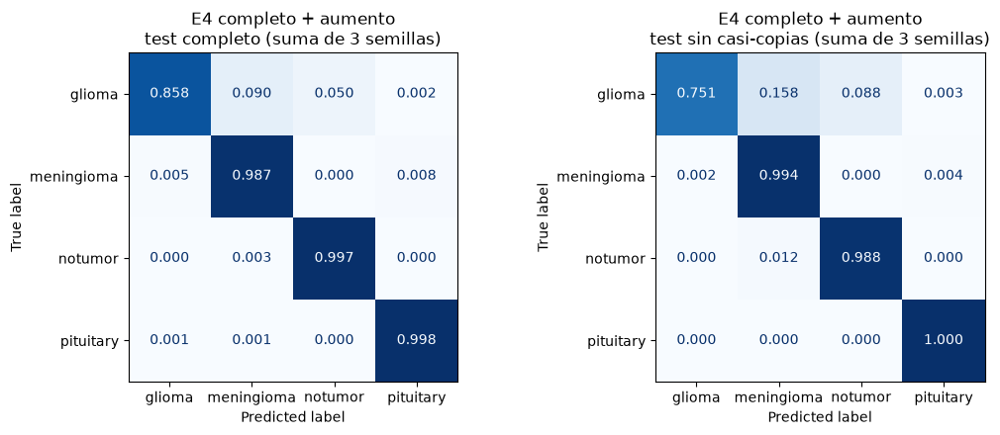

In [70]:
nombre = "E4 completo + aumento"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titulo, mask) in zip(axes, (("completo", np.ones_like(limpio)), ("sin casi-copias", limpio))):
    cm = sum(confusion_matrix(y_final[mask], yp[mask], labels=range(4)) for yp in preds[nombre])
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=clases).plot(
        ax=ax, values_format=".3f", cmap="Blues", colorbar=False)
    ax.set_title(f"{nombre}\n{SPLIT_FINAL} {titulo} (suma de 3 semillas)")
plt.tight_layout(); plt.show()

In [71]:
print(classification_report(y_final[limpio], preds["E4 completo + aumento"][0][limpio],
                            target_names=clases, digits=3))

              precision    recall  f1-score   support

      glioma      0.994     0.751     0.856       213
  meningioma      0.822     0.994     0.900       158
     notumor      0.565     0.963     0.712        27
   pituitary      1.000     1.000     1.000       193

    accuracy                          0.907       591
   macro avg      0.845     0.927     0.867       591
weighted avg      0.930     0.907     0.908       591



### Resultados

| Modelo | F1 val | F1 test | F1 test limpio |
|---|---|---|---|
| E1 QDA | 0,8016 | 0,7499 | 0,6332 |
| E3 linear probing | 0,8953  | 0,8250  | 0,7225  |
| E2 CNN | 0,9553  | 0,9068  | 0,8089  |
| E3 layer4 | 0,9592  | 0,9105  | 0,8138  |
| E4 CNN + aumento | 0,9696  | 0,9177 | 0,8268  |
| E3 completo | 0,9812  | 0,9268  | 0,8376  |
| E4 layer4 + aumento | 0,9745  | 0,9340  | 0,8515  |
| **E4 completo + aumento** | **0,9894** | **0,9442** | **0,8727** |

- **El mejor modelo en test es el mismo que en validación:** ResNet18 con fine-tuning completo y aumento de datos, con F1 macro 0,9442 y 0,8727 en el test limpio.
- **El orden de los modelos se mantiene.** El único cambio es entre E3 completo y E4 layer4 + aumento, que ya estaban prácticamente empatados en val. Por tanto, las conclusiones de E3 y E4 se confirman en test: el modelo preentrenado con finetunning mejora a la CNN desde cero, entrenar toda la red es mejor que solo layer4, y el aumento de datos mejora los tres modelos a los que se aplica.
- **Todos los modelos pierden unos 5 puntos de F1 entre val y test**, y unos 10 puntos en el test limpio. Una caída tan uniforme sugiere que no es un problema de un modelo concreto sino de los datos de test.

## Análisis de errores fuera de los resultados

La caída en el test limpio podría interpretarse como que las casi-copias inflaban el resultado del test completo. Antes de aceptarlo, comprobamos si el test limpio es más difícil por estar más lejos de train o por otro motivo.

Toda la experimentación a partir de este momento se realiza con el objetivo de entender porque todos los modelos han sufrido una caída tan drastica en el test. Lo aprendido en este apartado no se ha aplicado en ningún caso para modificar ni mejorar el trabajo realizado hasta el momento. 

In [72]:
s = pd.read_csv("splits.csv")
Hs = np.stack([phash(r) for r in s["ruta"]]).astype(np.float32)
sp = s["split"].to_numpy()
tr, va = sp == "train", sp == "val"
te_limpio = (sp == "test") & ~s["casi_copia"].to_numpy(dtype=bool)

def d_min(a, b):
    return (Hs[a] @ (1 - Hs[b]).T + (1 - Hs[a]) @ Hs[b].T).min(axis=1)

display(pd.DataFrame({"val -> train": pd.Series(d_min(va, tr)).describe(),
                      "test limpio -> train+val": pd.Series(d_min(te_limpio, tr | va)).describe()}).round(1))

,val -> train,test limpio -> train+val
count,1127.0,591.0
mean,9.8,9.9
std,2.0,2.2
min,8.0,8.0
25%,8.0,8.0
50%,10.0,10.0
75%,10.0,12.0
max,20.0,18.0


Gliomas del test limpio según la fracción de modelos que los fallan:
0.0    110
0.1     20
0.2      7
0.3      4
0.4      5
0.5      4
0.6      3
0.7      3
0.8      8
0.9      7
1.0     42
Name: count, dtype: int64


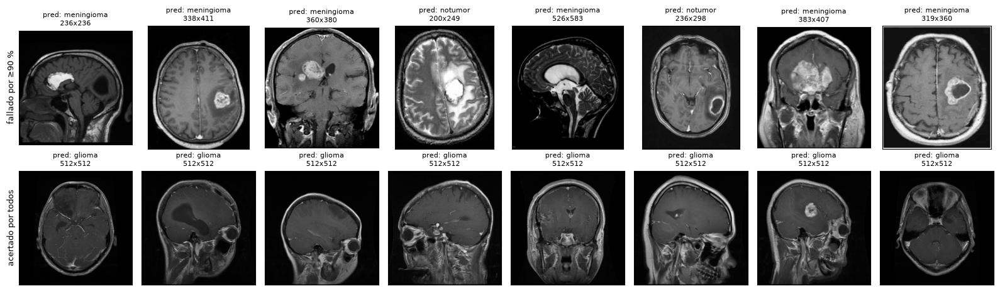

In [73]:
todos = np.stack([yp for n in redes for yp in preds[n]])      # (21 modelos, N imágenes)
err = (todos != y_final).mean(axis=0)                          # fracción de modelos que falla cada imagen
gl = limpio & (y_final == clase_a_idx["glioma"])
print("Gliomas del test limpio según la fracción de modelos que los fallan:")
print(pd.Series(err[gl]).round(1).value_counts().sort_index())

ruta_f = sub_final["ruta"].to_numpy()
grupos = {"fallado por ≥90 %": np.where(gl & (err >= 0.9))[0][:8],
          "acertado por todos": np.where(gl & (err == 0))[0][:8]}
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for fila, (titulo, idx) in enumerate(grupos.items()):
    for ax, k in zip(axes[fila], idx):
        img = Image.open(ruta_f[k])
        ax.imshow(img.convert("L"), cmap="gray")
        ax.set_title(f"pred: {clases[np.bincount(todos[:, k], minlength=4).argmax()]}\n{img.size[0]}x{img.size[1]}", fontsize=8)
    axes[fila, 0].set_ylabel(titulo, fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

E4 completo + aumento, semilla 0: 58 errores de 1179 (3 con casi-copia, 55 sin)


predicha,glioma,meningioma,notumor,pituitary,All
real,,,,,
glioma,0,33,20,0,53
meningioma,1,0,0,1,2
notumor,0,1,0,0,1
pituitary,1,1,0,0,2
All,2,35,20,1,58


,ruta,real,predicha,casi_copia
0,rfa_data/Testing/glioma/Te-gl_102.jpg,glioma,notumor,False
1,rfa_data/Testing/glioma/Te-gl_106.jpg,glioma,meningioma,False
2,rfa_data/Testing/glioma/Te-gl_109.jpg,glioma,meningioma,False
3,rfa_data/Testing/glioma/Te-gl_115.jpg,glioma,meningioma,False
4,rfa_data/Testing/glioma/Te-gl_126.jpg,glioma,meningioma,False
5,rfa_data/Testing/glioma/Te-gl_129.jpg,glioma,meningioma,False
6,rfa_data/Testing/glioma/Te-gl_133.jpg,glioma,meningioma,False
7,rfa_data/Testing/glioma/Te-gl_143.jpg,glioma,notumor,False
8,rfa_data/Testing/glioma/Te-gl_15.jpg,glioma,meningioma,False
9,rfa_data/Testing/glioma/Te-gl_151.jpg,glioma,meningioma,False


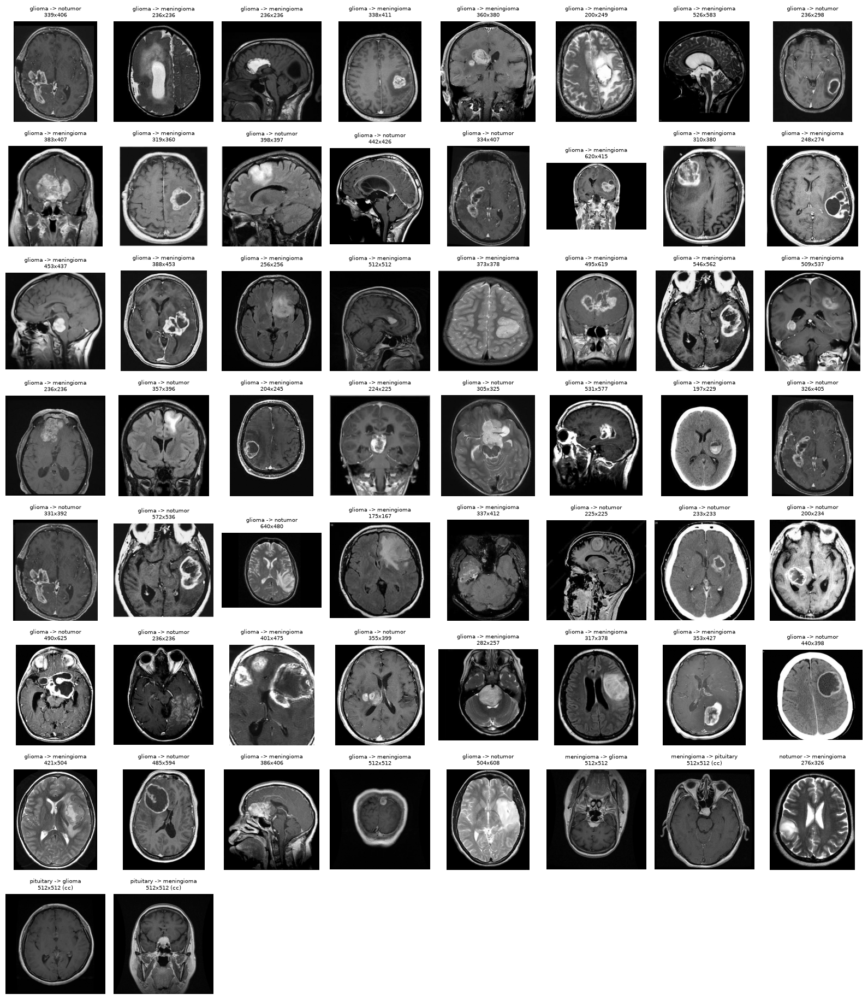

In [74]:
MODELO, SEMILLA = "E4 completo + aumento", 0
yp = preds[MODELO][SEMILLA]
mal = np.where(yp != y_final)[0]
mal = mal[np.argsort(y_final[mal], kind="stable")]   # agrupados por clase real

errores = pd.DataFrame({
    "ruta":       sub_final["ruta"].to_numpy()[mal],
    "real":       [clases[i] for i in y_final[mal]],
    "predicha":   [clases[i] for i in yp[mal]],
    "casi_copia": ~limpio[mal],
})
print(f"{MODELO}, semilla {SEMILLA}: {len(mal)} errores de {len(yp)} "
      f"({errores['casi_copia'].sum()} con casi-copia, {(~errores['casi_copia']).sum()} sin)")
display(pd.crosstab(errores["real"], errores["predicha"], margins=True))
display(errores)

# Imágenes: título "real -> predicha", tamaño original y (cc) si tiene casi-copia
N, cols = min(len(mal), 64), 8
filas = (N + cols - 1) // cols
fig, axes = plt.subplots(filas, cols, figsize=(2 * cols, 2.3 * filas), squeeze=False)
for ax, k in zip(axes.flat, mal[:N]):
    img = Image.open(sub_final["ruta"].iloc[k])
    ax.imshow(img.convert("L"), cmap="gray")
    ax.set_title(f"{clases[y_final[k]]} -> {clases[yp[k]]}\n{img.size[0]}x{img.size[1]}"
                 + ("" if limpio[k] else " (cc)"), fontsize=7)
for ax in axes.flat:
    ax.set_axis_off()
plt.tight_layout(); plt.show()

In [75]:
s = pd.read_csv("splits.csv")
s["512x512"] = [Image.open(r).size == (512, 512) for r in s["ruta"]]

# ¿Qué fracción de cada clase es 512x512 en train, val y test?
display(pd.crosstab([s["split"], s["clase"]], s["512x512"], margins=True))

# En los gliomas del test limpio: ¿fallan sobre todo los que no son 512x512?
es512 = np.array([Image.open(r).size == (512, 512) for r in ruta_f])
display(pd.crosstab(es512[gl], err[gl] >= 0.5,
                    rownames=["512x512"], colnames=["fallado por la mayoría de modelos"]))

512x512           False  True   All
split clase                        
test  glioma         62   314   376
      meningioma     12   280   292
      notumor       111     2   113
      pituitary       8   390   398
train glioma          0  1003  1003
      meningioma     90   958  1048
      notumor       730    12   742
      pituitary      36  1063  1099
val   glioma          0   390   390
      meningioma     30   289   319
      notumor       167     1   168
      pituitary      10   240   250
All                1256  4942  6198

fallado por la mayoría de modelos,False,True
512x512,,
False,2,60
True,146,5


In [76]:
otra = (y_final == clase_a_idx["glioma"]) & ~es512    # gliomas de test que no son 512x512 (62)
print(f"{otra.sum()} gliomas de otra fuente, {(otra & limpio).sum()} de ellos en el test limpio")

for s, yp in enumerate(preds["E4 completo + aumento"]):
    fallo = yp != y_final
    resto, resto_limpio = ~otra, limpio & ~otra
    print(f"semilla {s}: {fallo.sum()} errores, {(fallo & otra).sum()} en los gliomas de otra fuente | "
          f"acierto en el resto: {accuracy_score(y_final[resto], yp[resto]):.4f} ({resto.sum()} img.), "
          f"en el resto limpio: {accuracy_score(y_final[resto_limpio], yp[resto_limpio]):.4f} ({resto_limpio.sum()} img.)")

62 gliomas de otra fuente, 62 de ellos en el test limpio
semilla 0: 58 errores, 51 en los gliomas de otra fuente | acierto en el resto: 0.9937 (1117 img.), en el resto limpio: 0.9924 (529 img.)
semilla 1: 57 errores, 51 en los gliomas de otra fuente | acierto en el resto: 0.9946 (1117 img.), en el resto limpio: 0.9962 (529 img.)
semilla 2: 59 errores, 53 en los gliomas de otra fuente | acierto en el resto: 0.9946 (1117 img.), en el resto limpio: 0.9962 (529 img.)


In [77]:
for n in ("E2 CNN", "E4 CNN + aumento", "E3 completo", "E4 completo + aumento"):
    acc = [(yp[otra] == y_final[otra]).mean() for yp in preds[n]]
    print(f"{n:24s} acierto en los 62 gliomas de otra fuente: {np.mean(acc):.3f}")

E2 CNN                   acierto en los 62 gliomas de otra fuente: 0.075
E4 CNN + aumento         acierto en los 62 gliomas de otra fuente: 0.118
E3 completo              acierto en los 62 gliomas de otra fuente: 0.065
E4 completo + aumento    acierto en los 62 gliomas de otra fuente: 0.167


### Qué explica la caída en test

**Las casi-copias no explican la caída.** La distancia pHash mínima a train es prácticamente igual para val que para el test limpio (media 9,8 frente a 9,9; mínimo 8 en ambos). Es decir, el test limpio no está más lejos de los datos de entrenamiento que la validación y, sin embargo, el F1 baja de 0,99 a 0,87. Además, fuera de los gliomas que se describen abajo, el acierto del mejor modelo es prácticamente el mismo en el test completo que en el limpio.

**La explica un grupo de 62 gliomas de test.**
- En train y val todos los gliomas son de 512×512 (1393 imágenes); en test hay 62 que no lo son. Los 62 están en el test limpio, porque no se parecen a nada de train.
- Los modelos fallan casi todas: el mejor modelo acierta solo el 17 % de ellas, y las demás redes comprobadas entre el 6 % y el 12 %. 42 de los 213 gliomas del test limpio los fallan prácticamente todas las redes (al menos 20 de las 21 ejecuciones).
- Para el mejor modelo, estos 62 gliomas acumulan entre 51 y 53 de sus 57–59 errores según la semilla. **En el resto del test (1117 imágenes) el acierto es del 99,4–99,5 %**, en línea con validación.

**Sin esos 62 gliomas, el test coincide con validación.** La tabla recoge el F1 macro de cada modelo (media de 3 semillas; E1 se entrena una sola vez) en validación, en el test completo, en el test limpio, en el test sin los 62 gliomas y en el test limpio sin los 62 gliomas. La última columna es la diferencia entre estas dos últimas, que mide solo el efecto de tener una casi-copia en train/val una vez descontados los 62 gliomas.

| Modelo | F1 val | F1 test | F1 test limpio | F1 test sin 62 | F1 test limpio sin 62 | Efecto casi-copias |
|---|---|---|---|---|---|---|
| E1 LDA (K=300) | 0,7518 | 0,6756 | 0,5654 | 0,7218 | 0,6711 | 0,0507 |
| E1 LogReg (K=300) | 0,7747 | 0,7061 | 0,5887 | 0,7527 | 0,6838 | 0,0690 |
| E1 QDA (K=500) | 0,8016 | 0,7499 | 0,6332 | 0,8090 | 0,7592 | 0,0498 |
| E2 CNN | 0,9553 | 0,9068 | 0,8089 | 0,9668 | 0,9499 | 0,0169 |
| E4 CNN + aumento | 0,9696 | 0,9177 | 0,8268 | 0,9759 | 0,9654 | 0,0104 |
| E3 linear probing | 0,8953 | 0,8250 | 0,7225 | 0,8821 | 0,8566 | 0,0255 |
| E3 layer4 | 0,9592 | 0,9105 | 0,8138 | 0,9697 | 0,9543 | 0,0154 |
| E3 completo | 0,9812 | 0,9268 | 0,8376 | 0,9882 | 0,9848 | 0,0034 |
| E4 layer4 + aumento | 0,9745 | 0,9340 | 0,8515 | 0,9874 | 0,9802 | 0,0072 |
| **E4 completo + aumento** | **0,9894** | **0,9442** | **0,8727** | **0,9948** | **0,9945** | **0,0003** |


Al quitar los 62 gliomas, todas las redes recuperan entre 5,1 y 6,1 puntos de F1, y el resultado en test vuelve a estar en línea con validación: el mejor modelo pasa de 0,9442 a 0,9948, frente a 0,9894 en val. Además, con los 62 dentro, el mejor modelo cae 7,2 puntos del test al test limpio (0,9442 → 0,8727); sin ellos, solo 0,03 (0,9948 → 0,9945). Es coherente con que la distancia pHash mínima a train sea prácticamente igual para val que para el test limpio (media 9,8 frente a 9,9): la validación agrupada por pHash era una estimación fiable del rendimiento en la parte del test que sigue la distribución de train.


**Indicio de aprendizaje por atajo.** Es posible que los modelos hayan aprendido rasgos asociados a la fuente de la imagen y no solo al tumor. Encaja con la caída que hemos observado en el test al introducir imágenes con un formato no visto anteriormente. 

# Conclusiones

1. **Los datos son lo más importante.** El dataset combina tres fuentes y contiene copias exactas, copias recodificadas, casi-copias entre particiones y pares contradictorios entre clases. Sin la limpieza y la partición agrupada por pHash, la validación habría estado inflada por fugas. Aun así, el factor que más condiciona el resultado final no son las fugas, sino un cambio de distribución entre train y test que ninguna técnica de modelado corrige.
2. **Las redes convolucionales superan claramente a los métodos clásicos.** E1 se queda en un F1 de 0,802 en val, una CNN desde cero sencilla llega a 0,955 al explotar la estructura espacial de la imagen.
3. **El preentrenamiento ayuda, pero hay que adaptar la red.** Las características de ImageNet sin adaptar (*linear probing*) quedan por debajo de la CNN desde cero; con fine-tuning completo se obtienen los mejores resultados.
4. **El aumento de datos mejora todos los modelos** a los que se aplica, con todas las semillas, al reducir la memorización del conjunto de entrenamiento. Es complementario al preentrenamiento.
5. **Mejor modelo: ResNet18 con fine-tuning completo y aumento de datos.** F1 macro 0,989 en val y 0,944 en test, con un 99 % de acierto en todo el test salvo en los 62 gliomas de otra fuente.